In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset

In [2]:
import pandas as pd 
import sys 
import numpy as np 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.dataloader_fns import generate_quadrants, generate_dataloaders
from src.fdlbiomass.simple_conv import SimpleConv3D
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset 


# train_quadrants=[2,1]
# test_quadrant = 0
# val_quadrant=3

# parent_path = '/home/grace.bcolverd/esl_dev/tomosar-matlab'
# polarimetric_channel=['HV', 'VV', 'HH']
# quadrants, ground_truths, num_channels = generate_quadrants(parent_path, polarimetric_channels=polarimetric_channel  )
# train_loader, test_loader, val_loader, dataset, scaler = generate_dataloaders(quadrants, ground_truths, (64,64,36), (32,32,36), test_quadrant=3, batch_size=4, scaler_type='standard')

Starting to load the biomass data
Load complete
Original shape: (326, 840)
Cropped shape: (321, 665)
665 665
Quadrant shape: torch.Size([160, 332, 36, 1]) -> torch.Size([160, 352, 36, 1])
Ground truth shape: torch.Size([160, 332]) -> torch.Size([160, 352])
Quadrant shape: torch.Size([160, 333, 36, 1]) -> torch.Size([160, 352, 36, 1])
Ground truth shape: torch.Size([160, 333]) -> torch.Size([160, 352])
Quadrant shape: torch.Size([161, 332, 36, 1]) -> torch.Size([192, 352, 36, 1])
Ground truth shape: torch.Size([161, 332]) -> torch.Size([192, 352])
Quadrant shape: torch.Size([161, 333, 36, 1]) -> torch.Size([192, 352, 36, 1])
Ground truth shape: torch.Size([161, 333]) -> torch.Size([192, 352])
Total valid patches: 116
Quadrant 0: 25 valid patches
Quadrant 1: 40 valid patches
Quadrant 2: 27 valid patches
Quadrant 3: 24 valid patches
Dataset Initialization Information:
Patch size: (64, 64, 36)
Stride: (32, 32, 36)

Quadrant 0:
  Original shape: torch.Size([160, 332, 36, 1])
  Padded shape:

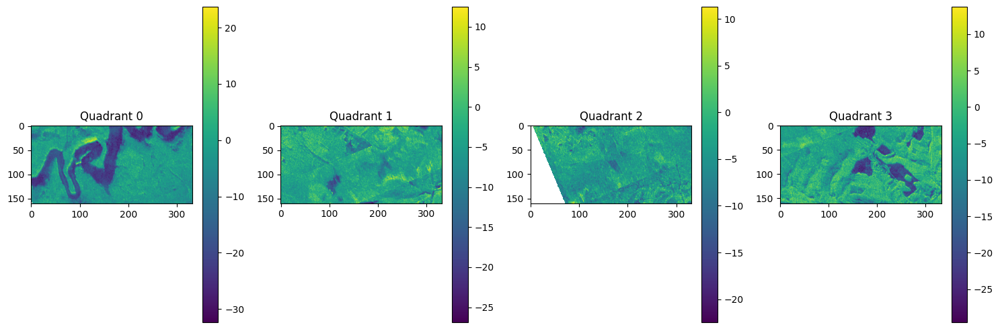

In [26]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from src.fdlbiomass.utils import merge_headings, load_biomass_data, split_into_quadrants, crop_to_non_nan
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset
from torch.utils.data import DataLoader

# Assuming the necessary imports from your scripts

parent_path = '/home/grace.bcolverd/esl_dev/tomosar-matlab'
polarimetric_channels = 'HH'
patch_size = (64, 64, 36)
stride = (32, 32, 36)
test_quadrant = 3
batch_size = 20
scaler_type = 'standard'

quadrants, ground_truths, num_channels = generate_quadrants(parent_path, polarimetric_channels)

# 2. Create dataset and dataloaders
train_loader, test_loader, val_loader, dataset, (input_scaler, gt_scaler), val_quad = generate_dataloaders(
    quadrants, ground_truths, patch_size, stride, test_quadrant, batch_size, scaler_type
)

# 3. Visualize original data
plt.figure(figsize=(15, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(quadrants[i][:,:,0,0])  # Assuming first channel, first depth slice
    plt.title(f"Quadrant {i}")
    plt.colorbar()
plt.tight_layout()
plt.show()

In [4]:
# Quadrant 0: 25 valid patches
# Quadrant 1: 40 valid patches
# Quadrant 2: 27 valid patches
# Quadrant 3: 24 valid patches

# 3: test
# 2; val 


In [5]:
for batch_idx, (batch_input, batch_target, mask) in enumerate(val_loader):
    print(batch_input.shape)

# for batch_idx, (batch_input, batch_target, mask) in enumerate(test_loader):
#     print(batch_input.shape)

# for batch_idx, (batch_input, batch_target, mask) in enumerate(train_loader):
#     print(batch_input.shape)

#     torch.Size([27, 3, 64, 64, 36])
# torch.Size([27, 3, 64, 64, 36])
# torch.Size([27, 3, 64, 64, 36])

torch.Size([20, 3, 64, 64, 36])
torch.Size([7, 3, 64, 64, 36])


In [6]:
for batch_idx, (batch_input, batch_target, mask) in enumerate(test_loader):
    print(batch_input.shape)

torch.Size([20, 3, 64, 64, 36])
torch.Size([4, 3, 64, 64, 36])


torch.Size([20, 3, 64, 64, 36])
torch.Size([20, 64, 64])
torch.Size([4, 3, 64, 64, 36])
torch.Size([4, 64, 64])


In [7]:
for batch_idx, (batch_input, batch_target, mask) in enumerate(train_loader):
    print(batch_input.shape)

torch.Size([20, 3, 64, 64, 36])
torch.Size([20, 3, 64, 64, 36])
torch.Size([20, 3, 64, 64, 36])
torch.Size([5, 3, 64, 64, 36])


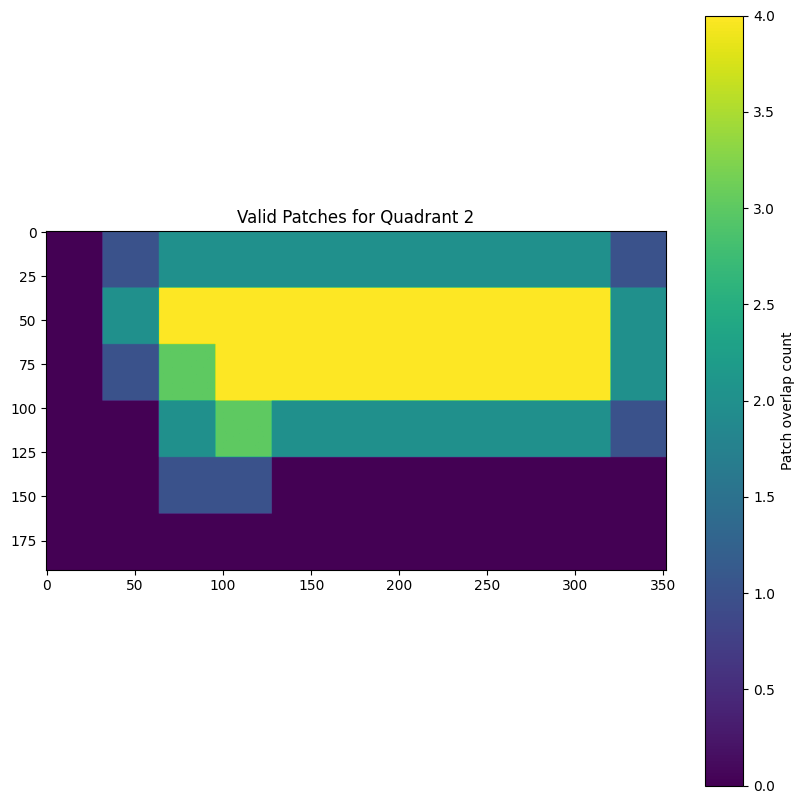

In [20]:
dataset.visualize_patches(2)

In [9]:
def print_dataloader_masks(dataloader, num_samples=None):
    """
    Print mask information for entries in a dataloader.
    
    :param dataloader: The dataloader to examine
    :param num_samples: Number of samples to print (None for all)
    """
    print(f"Examining masks in dataloader (mode: {dataloader.dataset.mode})")
    
    for i, (intensity, ground_truth, mask) in enumerate(dataloader):
        if num_samples is not None and i >= num_samples:
            break
        
        # Get the first item in the batch (assuming batch_size=1 for simplicity)
        mask = mask[0]
        
        total_elements = mask.numel()
        true_elements = mask.sum().item()
        false_elements = total_elements - true_elements
        
        print(f"Sample {i}:")
        print(f"  Mask shape: {mask.shape}")
        print(f"  True elements: {true_elements}/{total_elements} ({true_elements/total_elements*100:.2f}%)")
        print(f"  False elements: {false_elements}/{total_elements} ({false_elements/total_elements*100:.2f}%)")
        
        if torch.all(mask):
            print("  All elements are True")
        elif not torch.any(mask):
            print("  All elements are False")
        else:
            print("  Mask contains both True and False elements")
        
        print()  # Empty line for readability

    print("Examination complete.")

# Usage example:
# Assuming you have your dataloaders set up (train_loader, val_loader, test_loader)

print("Examining train loader:")
print_dataloader_masks(train_loader, num_samples=5)  # Print first 5 samples

print("\nExamining validation loader:")
print_dataloader_masks(val_loader, num_samples=5)  # Print first 5 samples

print("\nExamining test loader:")
print_dataloader_masks(test_loader, num_samples=5)  # Print first 5 samples

Examining train loader:
Examining masks in dataloader (mode: train)
Sample 0:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

Sample 1:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

Sample 2:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

Sample 3:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

Examination complete.

Examining validation loader:
Examining masks in dataloader (mode: val)
Sample 0:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

Sample 1:
  Mask shape: torch.Size([64, 64])
  True elements: 4096/4096 (100.00%)
  False elements: 0/4096 (0.00%)
  All elements are True

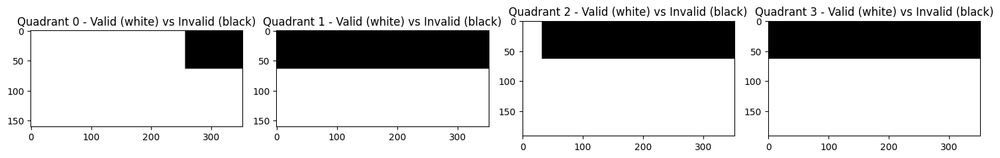

In [10]:
# 5. Visualize valid and invalid patches
def plot_patch_validity(dataset):
    plt.figure(figsize=(15, 5))
    for i in range(4):
        plt.subplot(1, 4, i+1)
        validity_map = np.zeros(dataset.padded_quadrants[i].shape[:2])
        for idx in dataset.valid_indices[i]:
            row = (idx // dataset.patches_per_quadrant) * dataset.stride[0]
            col = (idx % dataset.patches_per_quadrant) * dataset.stride[1]
            validity_map[row:row+patch_size[0], col:col+patch_size[1]] = 1
        plt.imshow(validity_map, cmap='binary')
        plt.title(f"Quadrant {i} - Valid (white) vs Invalid (black)")
    plt.tight_layout()
    plt.show()

plot_patch_validity(dataset)

Normalized Training Data:
norm shape  torch.Size([20, 1, 64, 64, 36])


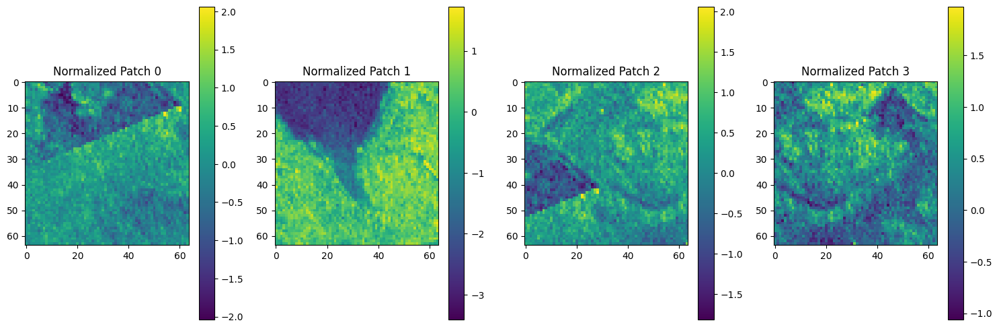

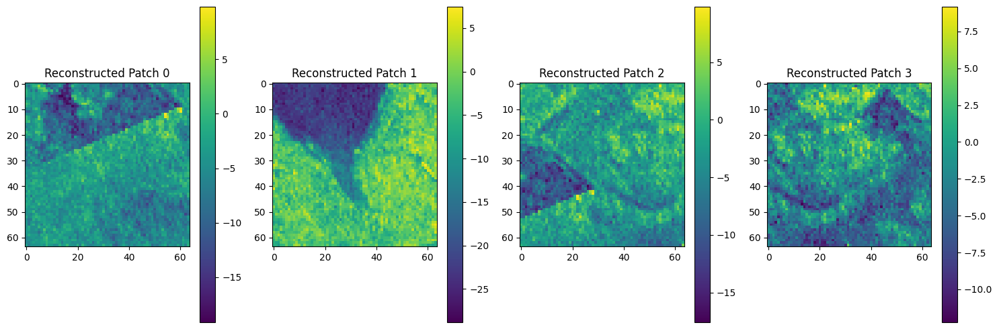

In [28]:

# 6. Check normalization
def plot_normalized_data(loader, scaler):
    batch = next(iter(loader))
    normalized_data = batch[0] 
    print('norm shape ', normalized_data.shape) # Assuming the first element is the input data
    plt.figure(figsize=(15, 5))
    for i in range(min(4, normalized_data.shape[0])):
        plt.subplot(1, 4, i+1)
        plt.imshow(normalized_data[i, 0, :, :, 0].numpy())  # Assuming first channel, first depth slice
        plt.title(f"Normalized Patch {i}")
        plt.colorbar()
    plt.tight_layout()
    plt.show()

    # Inverse transform and plot
    original_data = scaler.inverse_transform(normalized_data)
    plt.figure(figsize=(15, 5))
    for i in range(min(4, original_data.shape[0])):
        plt.subplot(1, 4, i+1)
        plt.imshow(original_data[i, 0, :, :, 0].numpy())
        plt.title(f"Reconstructed Patch {i}")
        plt.colorbar()
    plt.tight_layout()
    plt.show()

print("Normalized Training Data:")
plot_normalized_data(train_loader, input_scaler)

In [27]:
for batch_input, batch_target, mask in test_loader:
    print(batch_input.shape)
    print(batch_input[0, :, :, :, :].shape )

torch.Size([20, 1, 64, 64, 36])
torch.Size([1, 64, 64, 36])
torch.Size([4, 1, 64, 64, 36])
torch.Size([1, 64, 64, 36])


Visualizing Training Data:


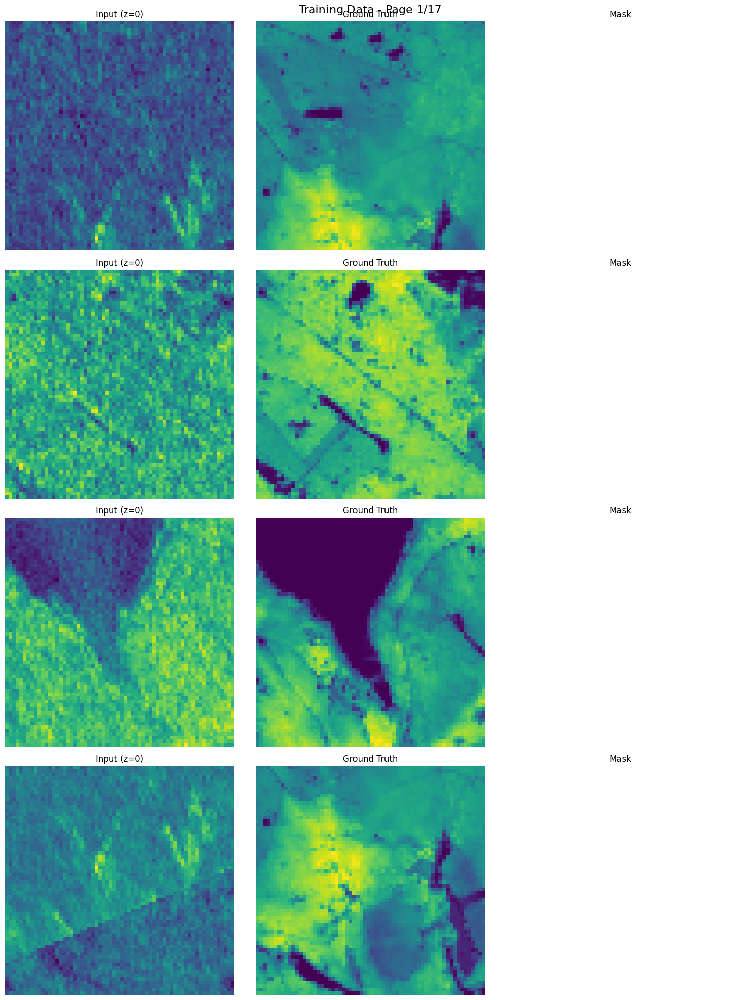

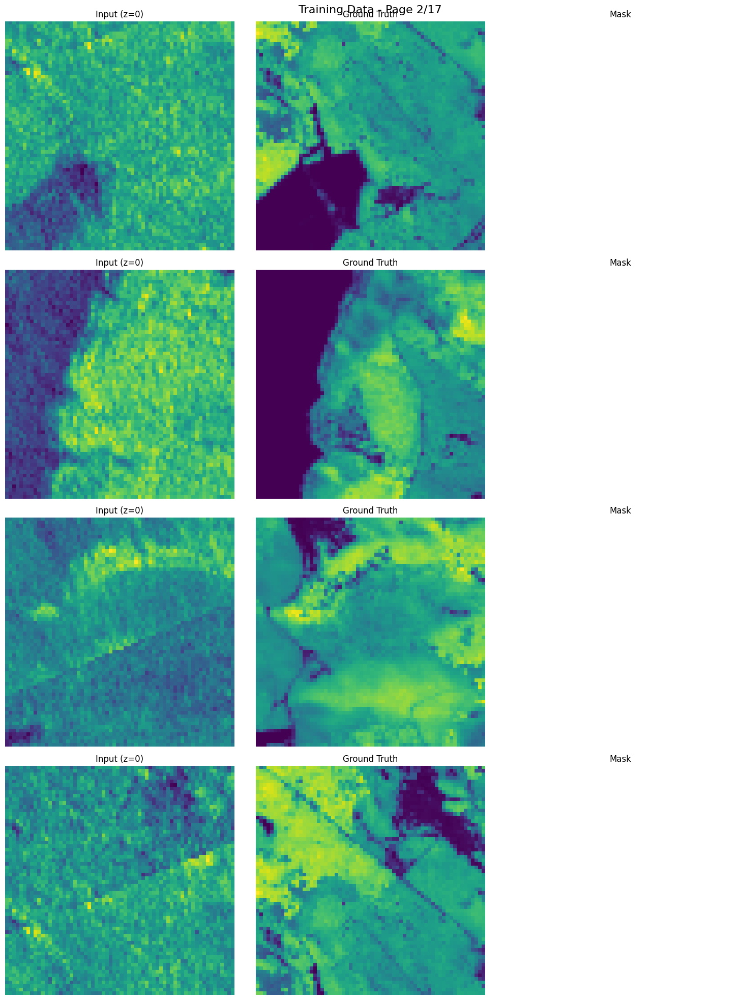

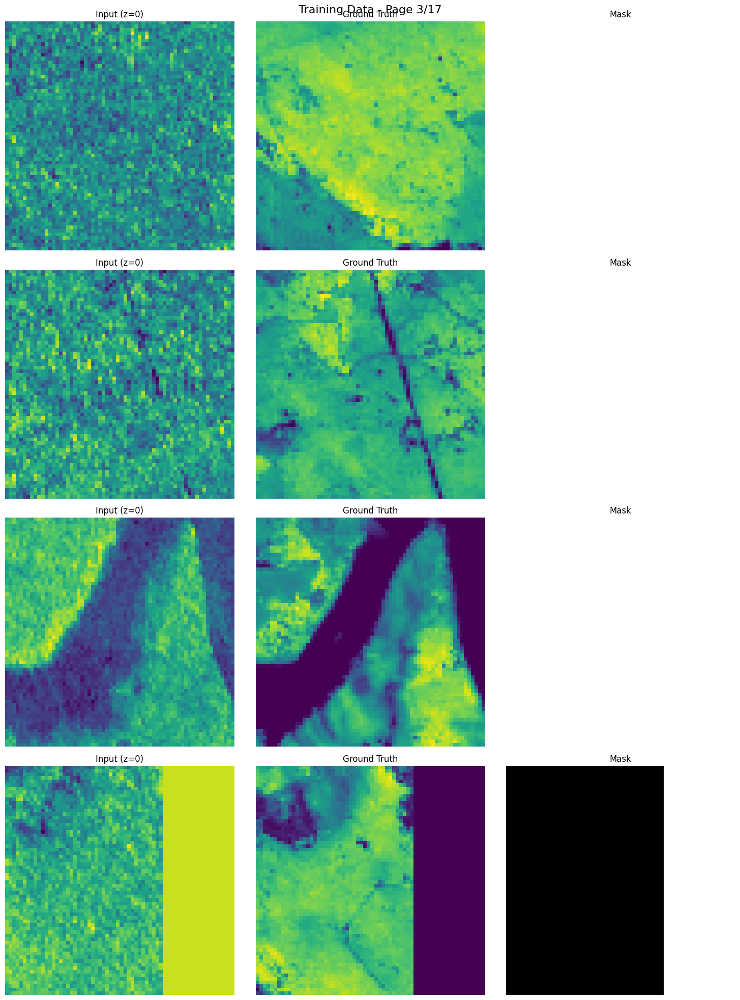

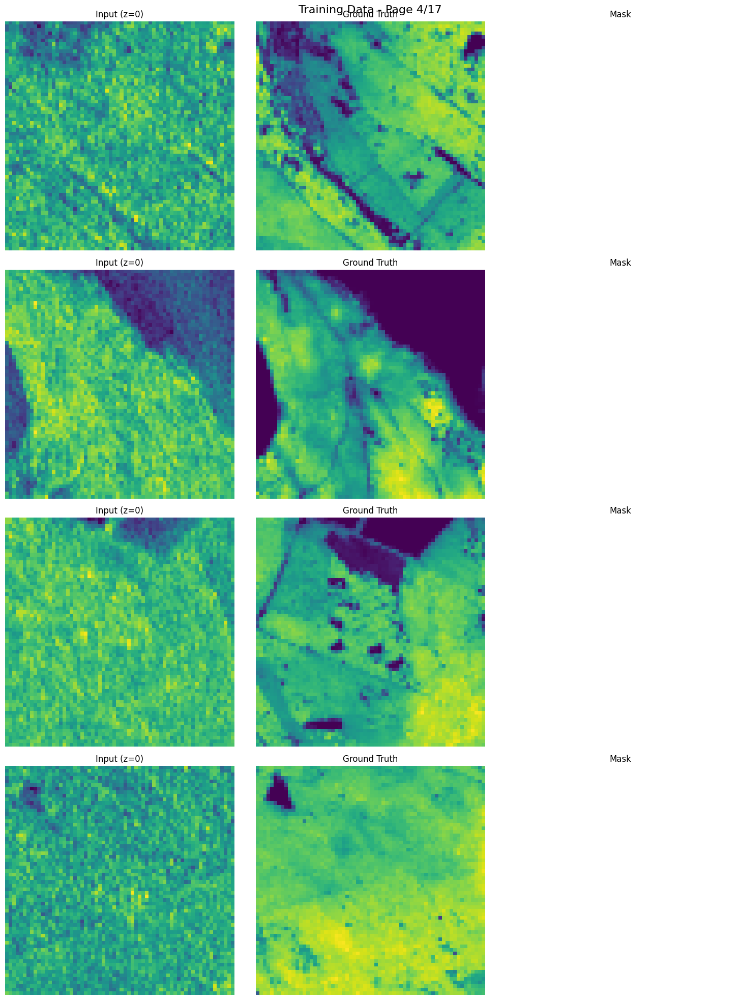

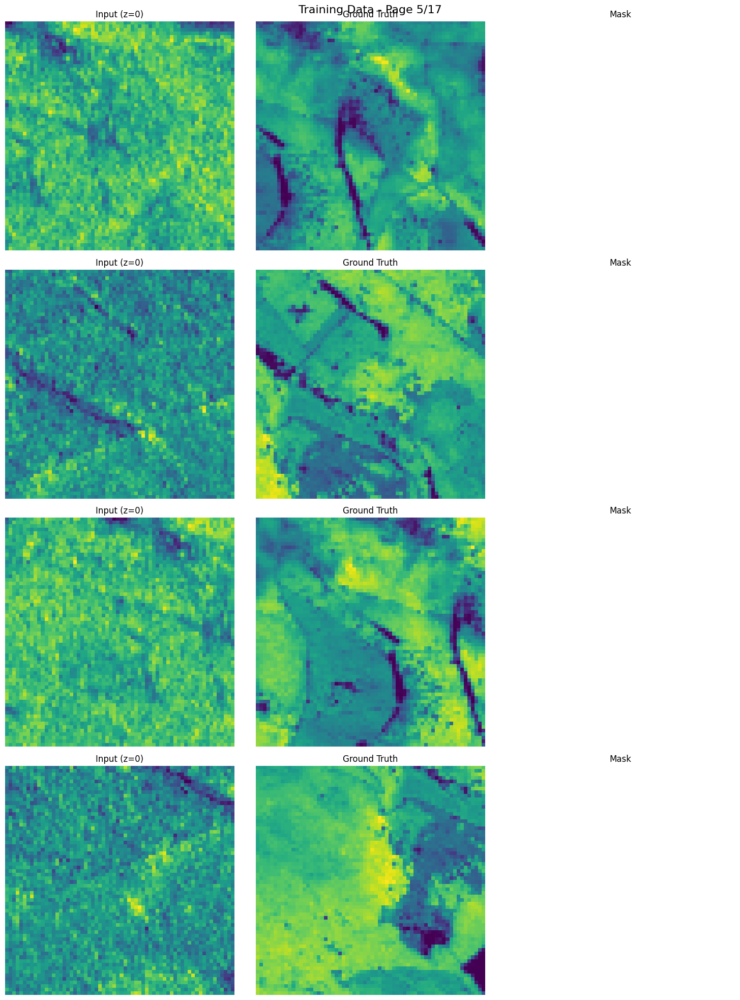

...

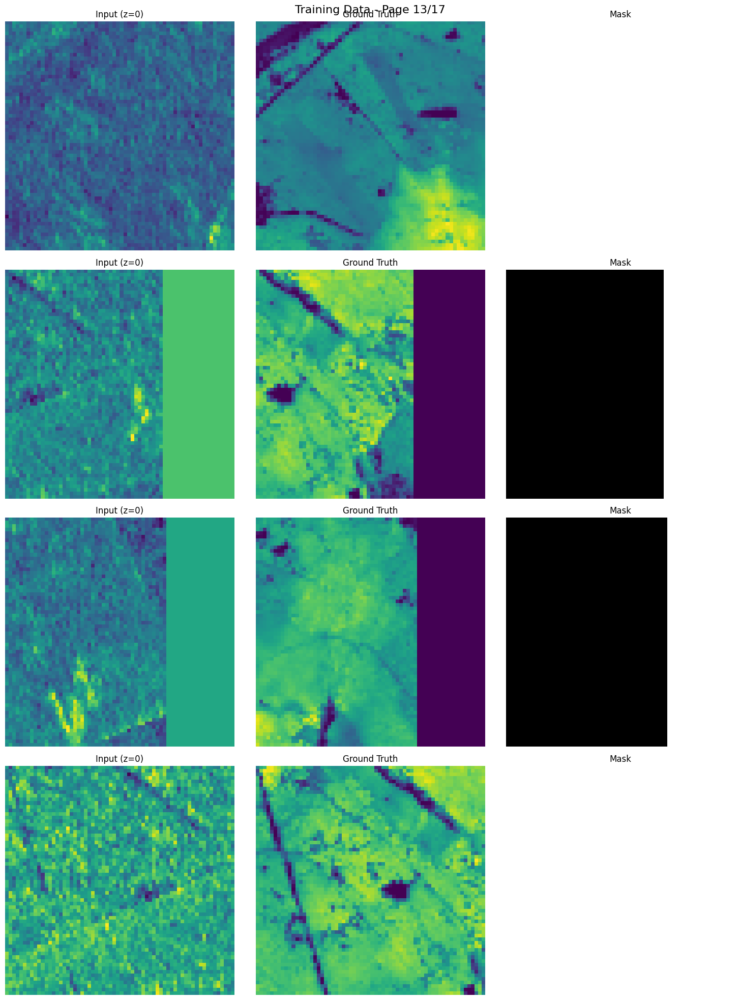

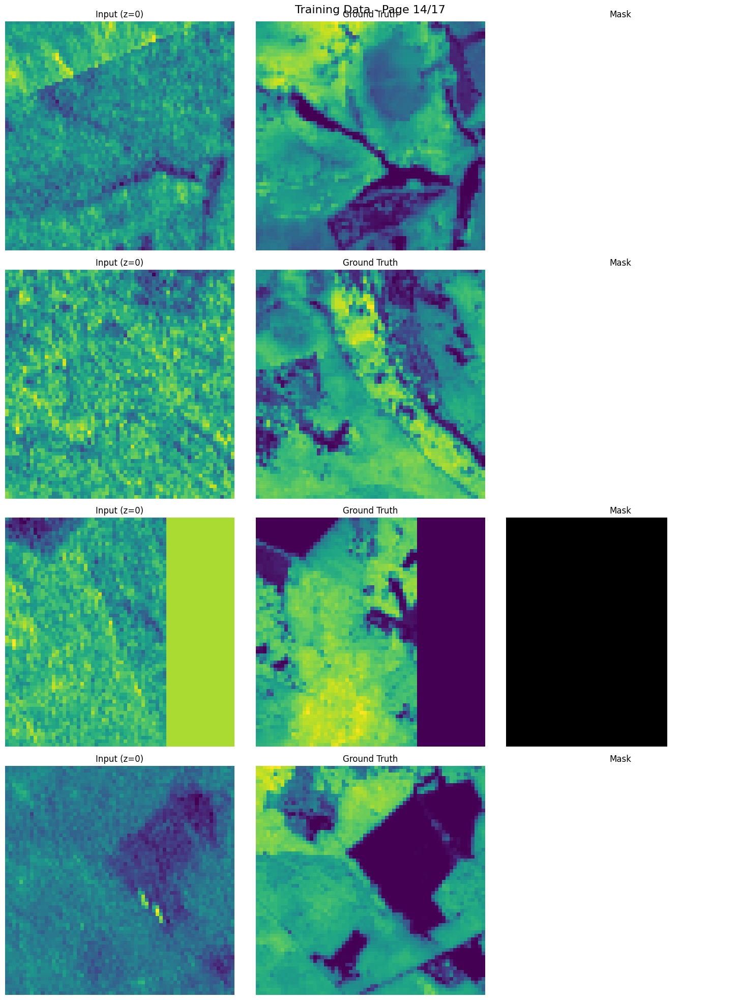

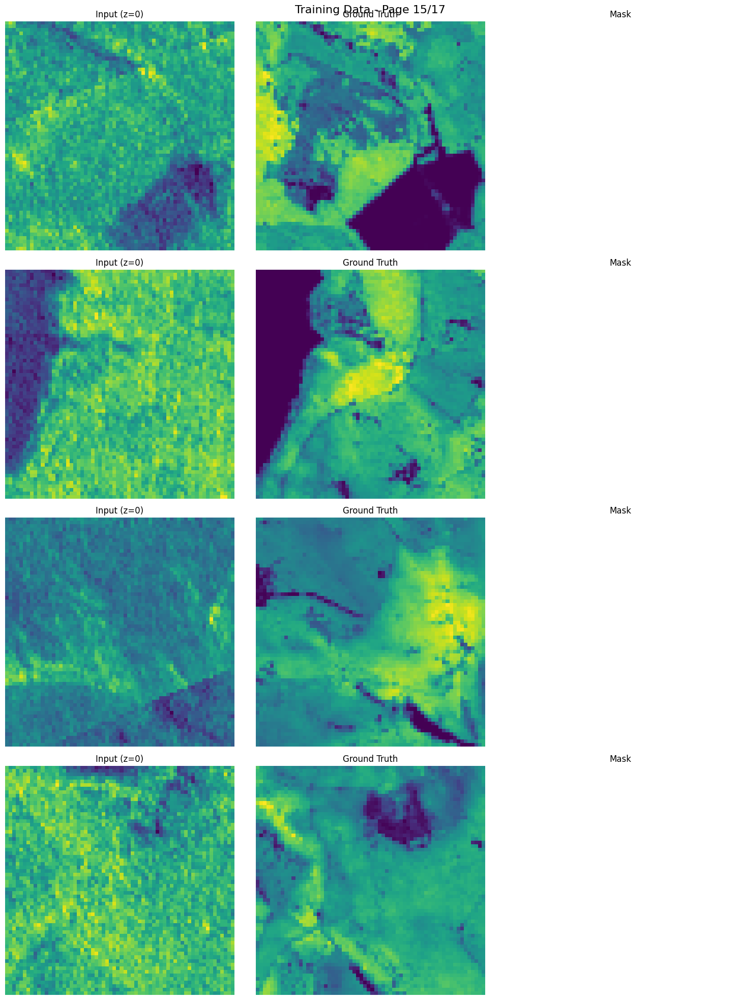

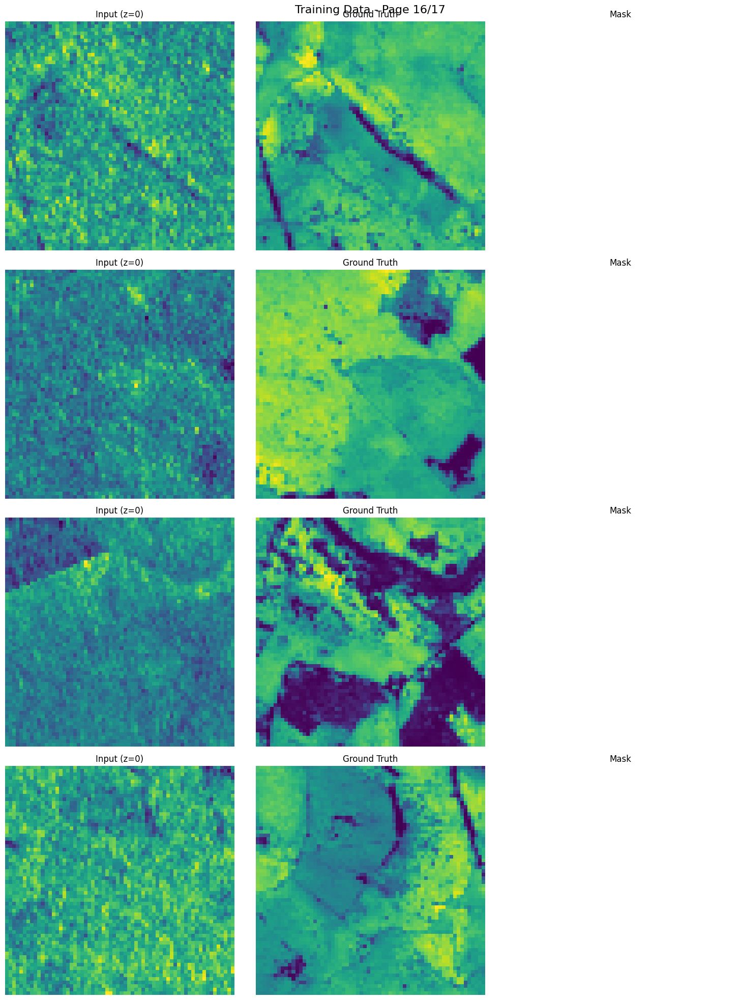

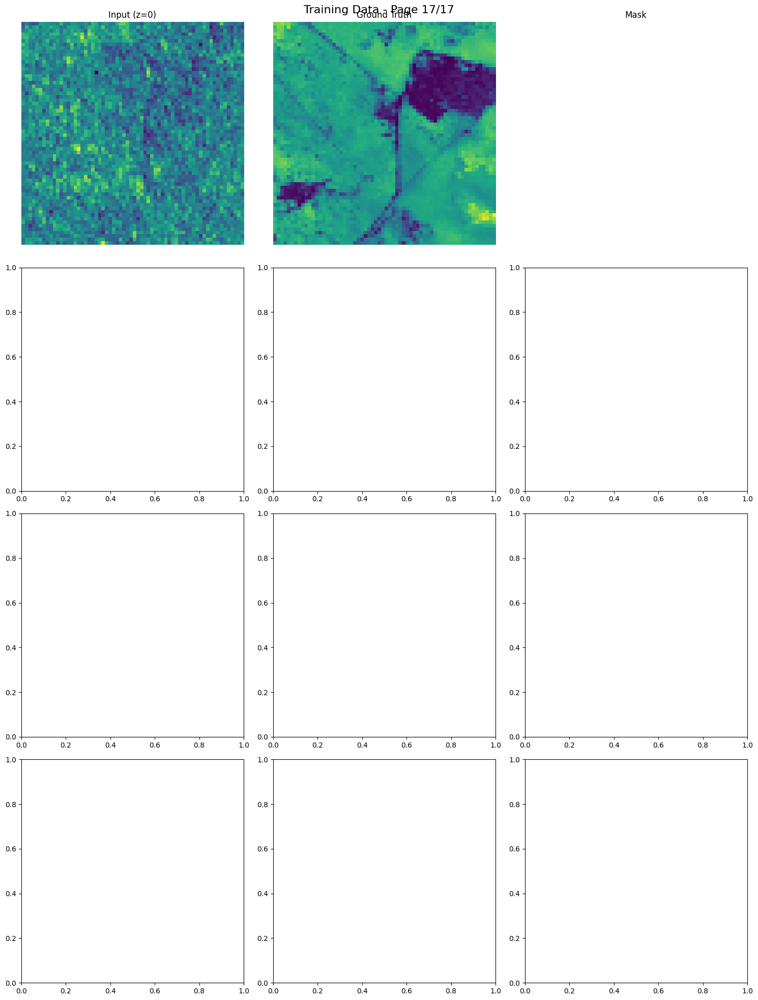

Total samples in Training Data: 65

Visualizing Validation Data:


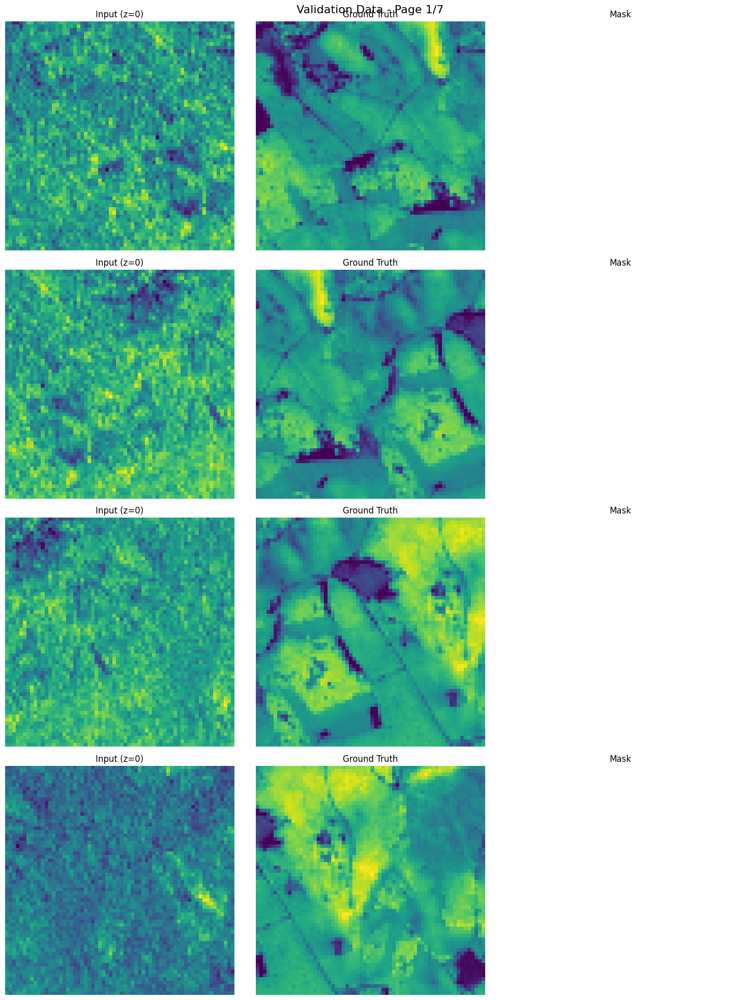

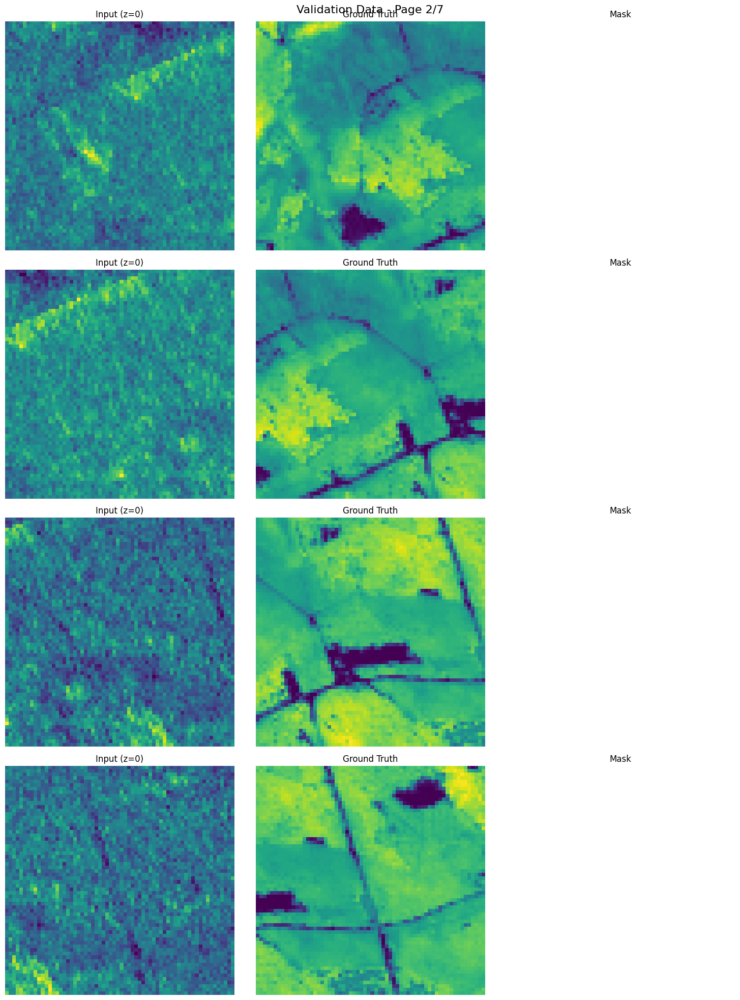

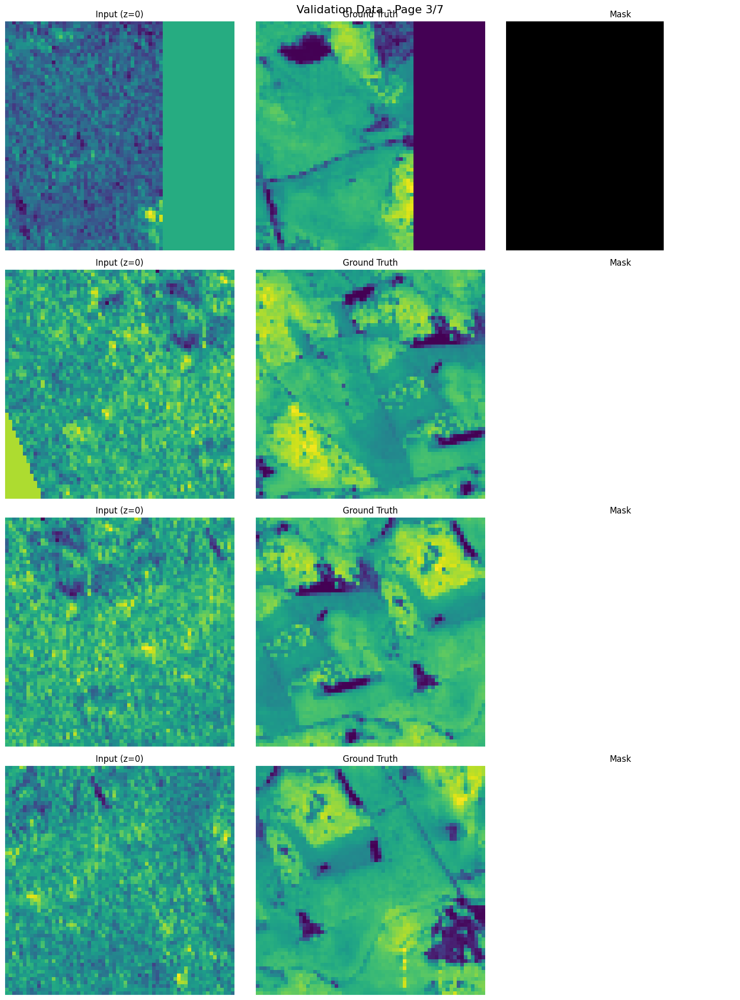

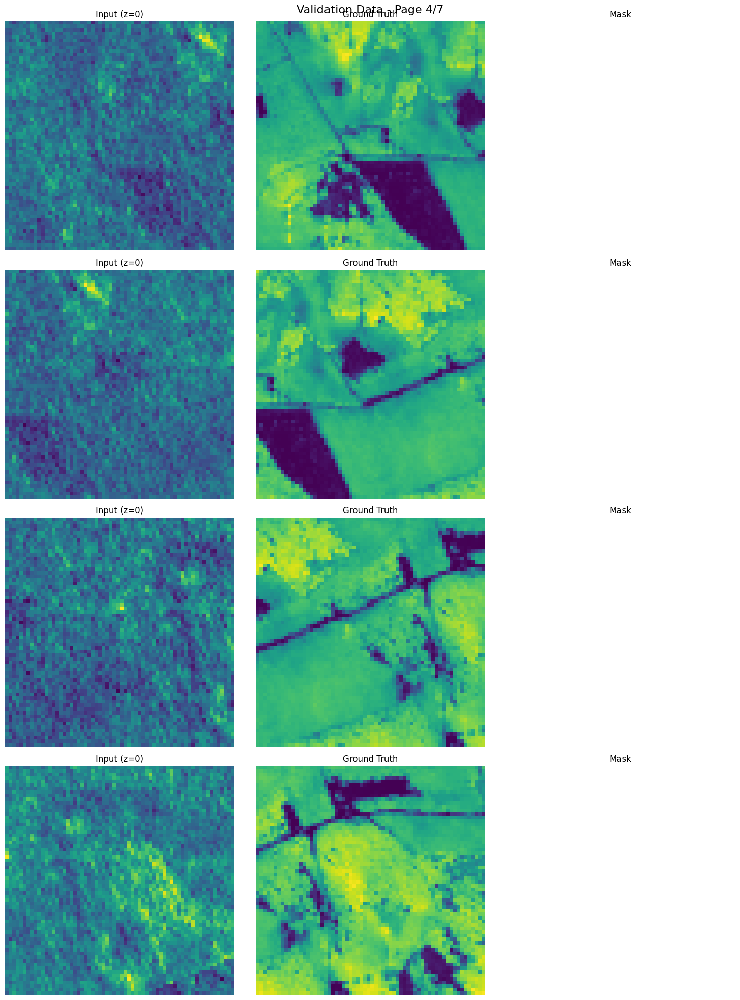

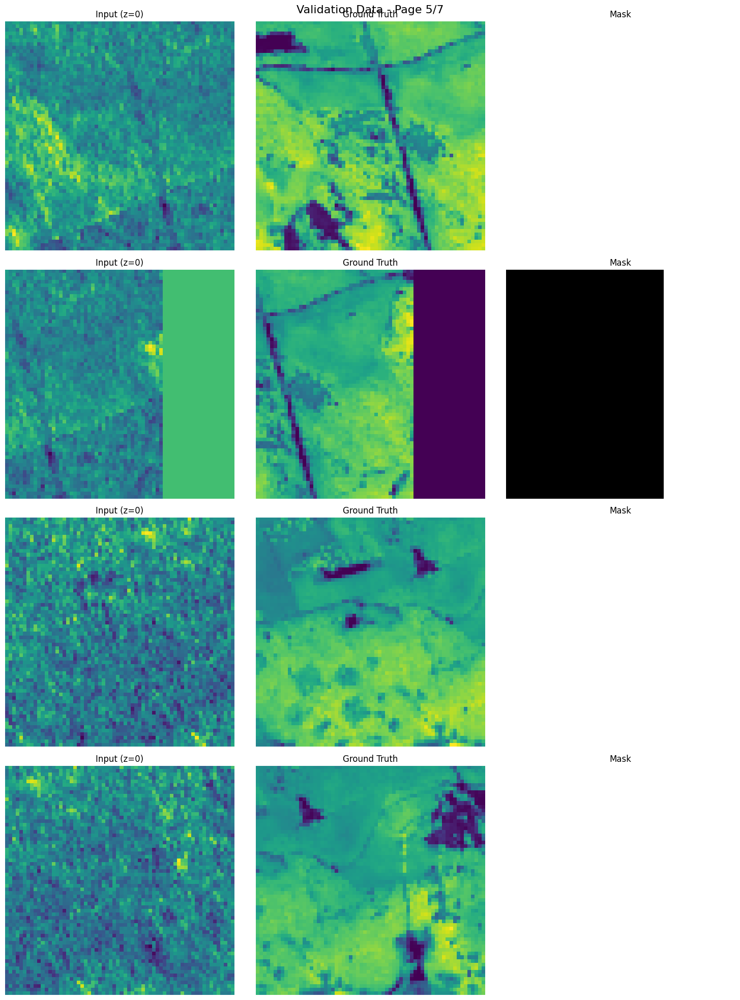

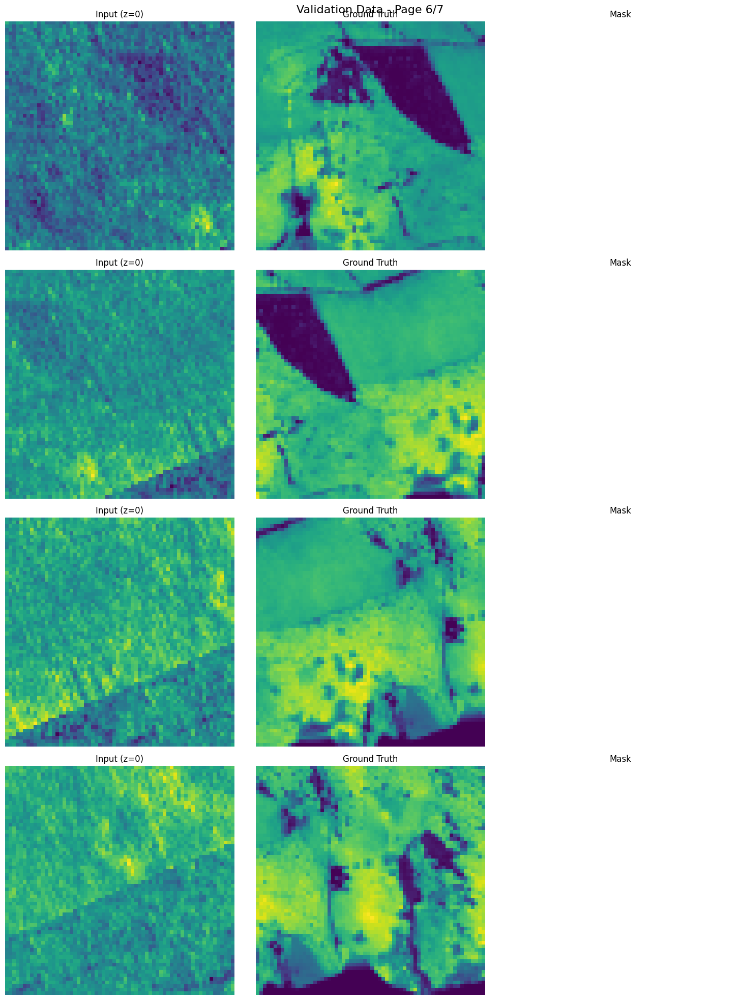

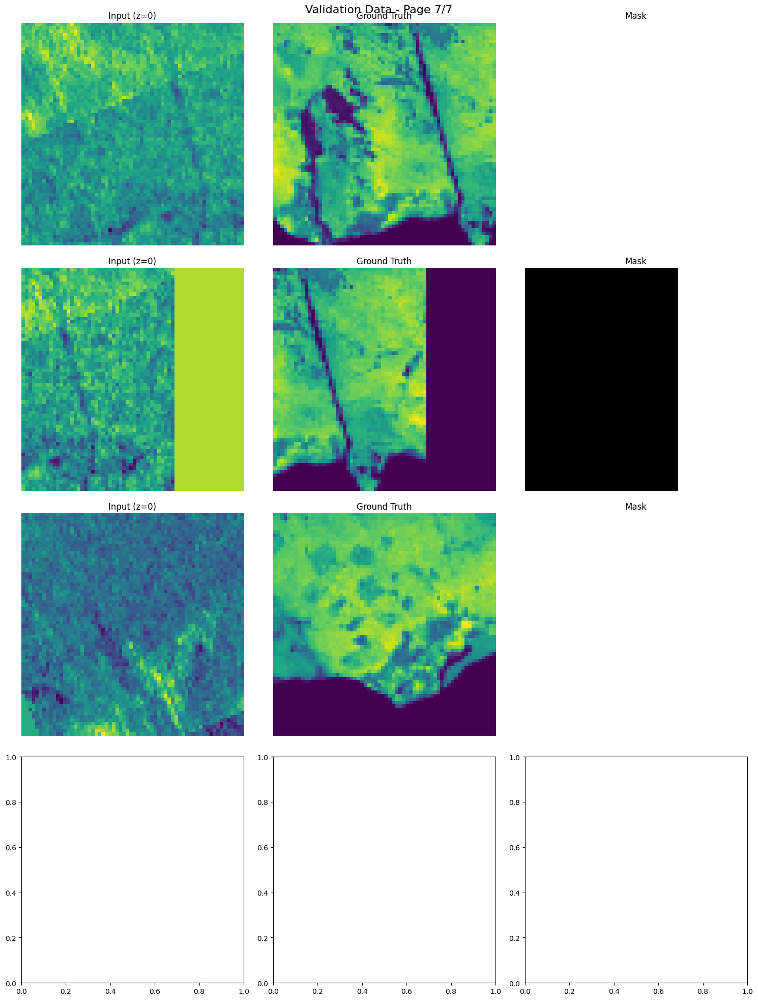

Total samples in Validation Data: 27

Visualizing Test Data:


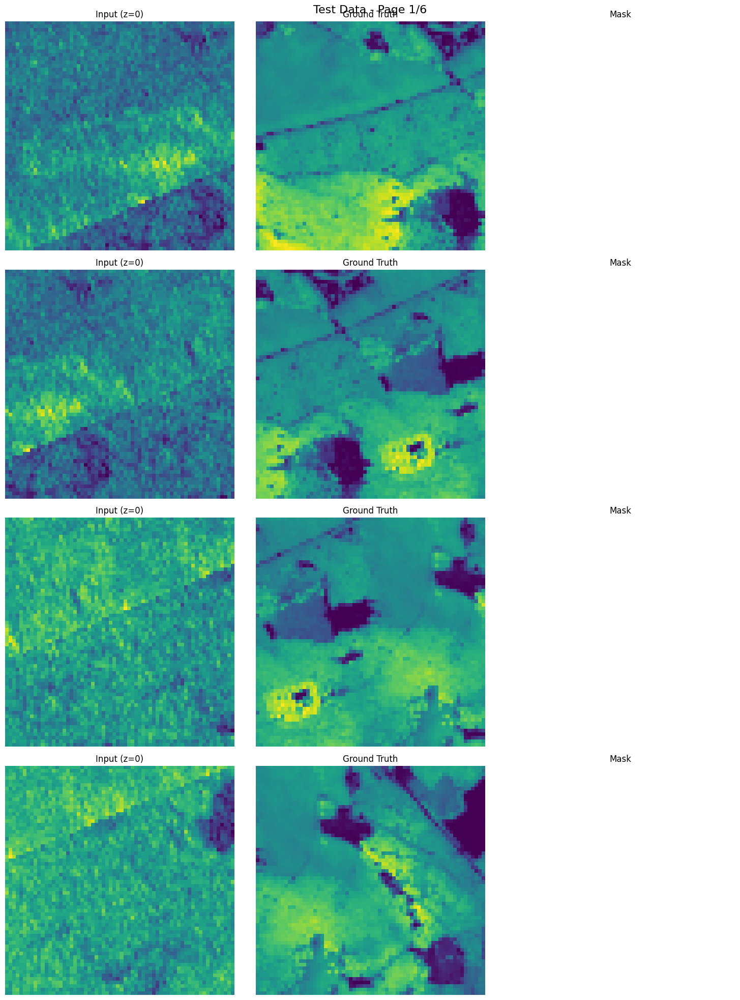

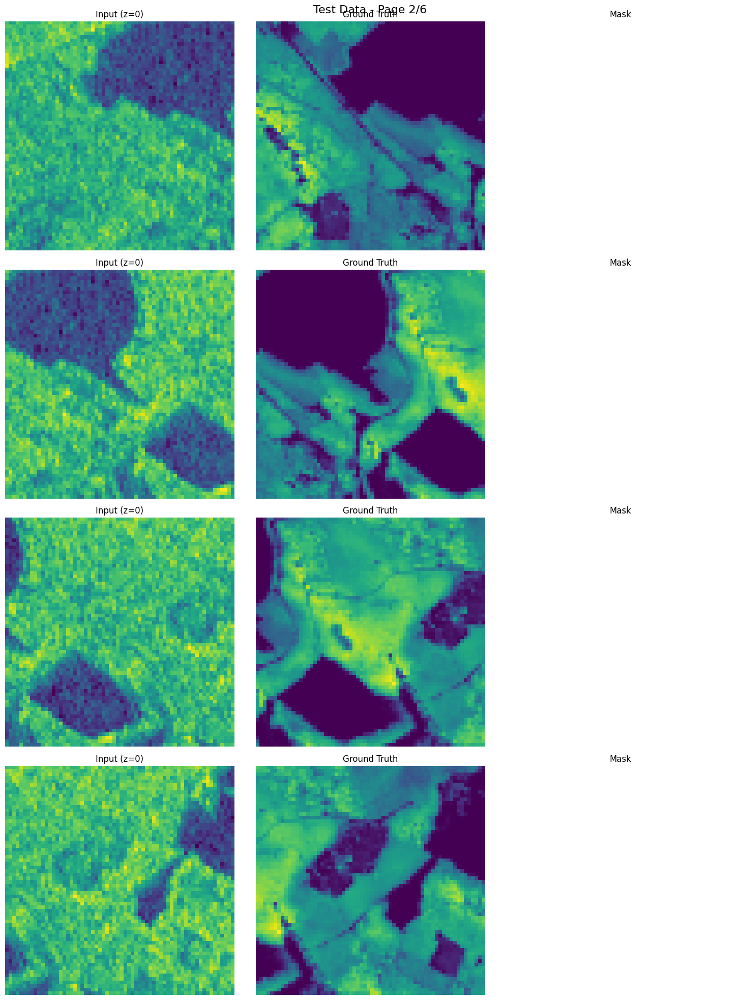

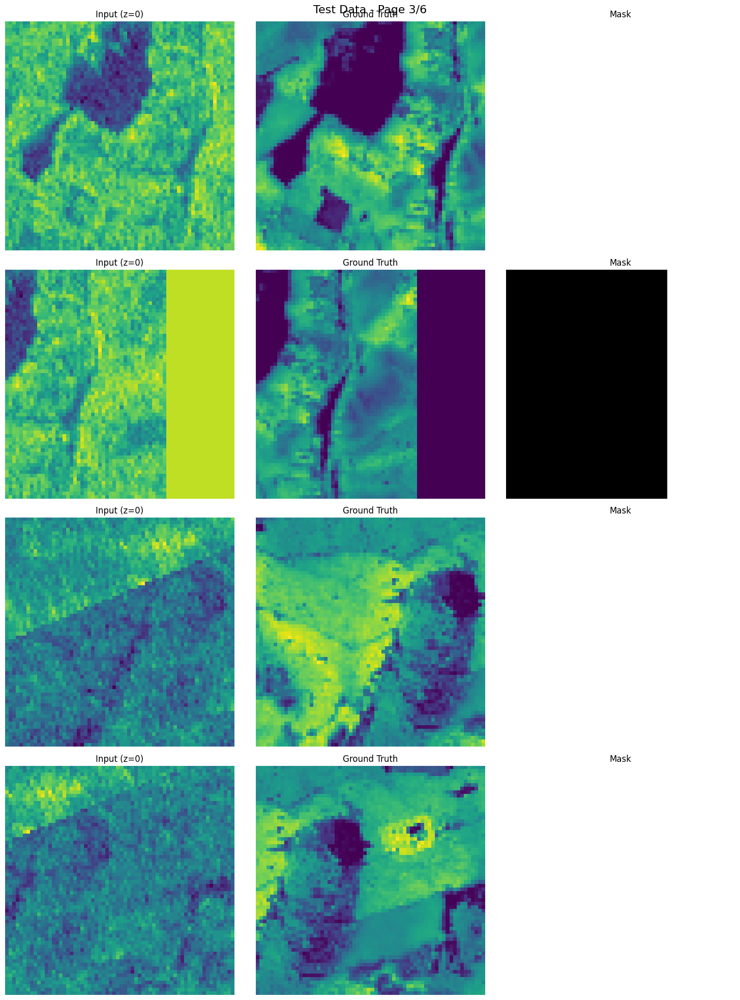

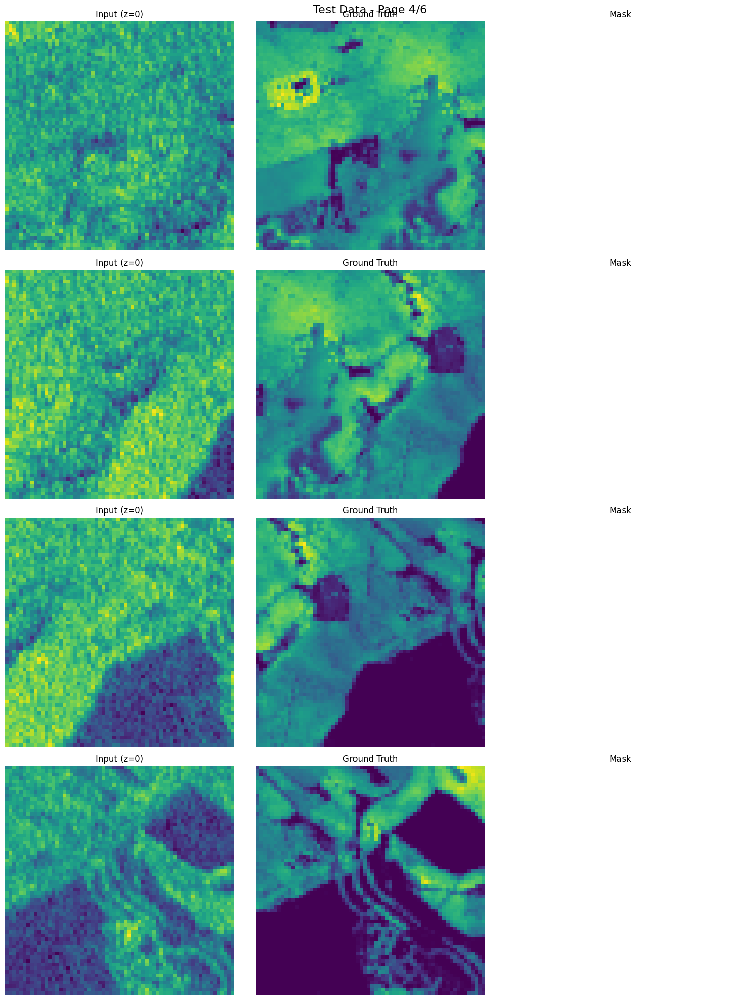

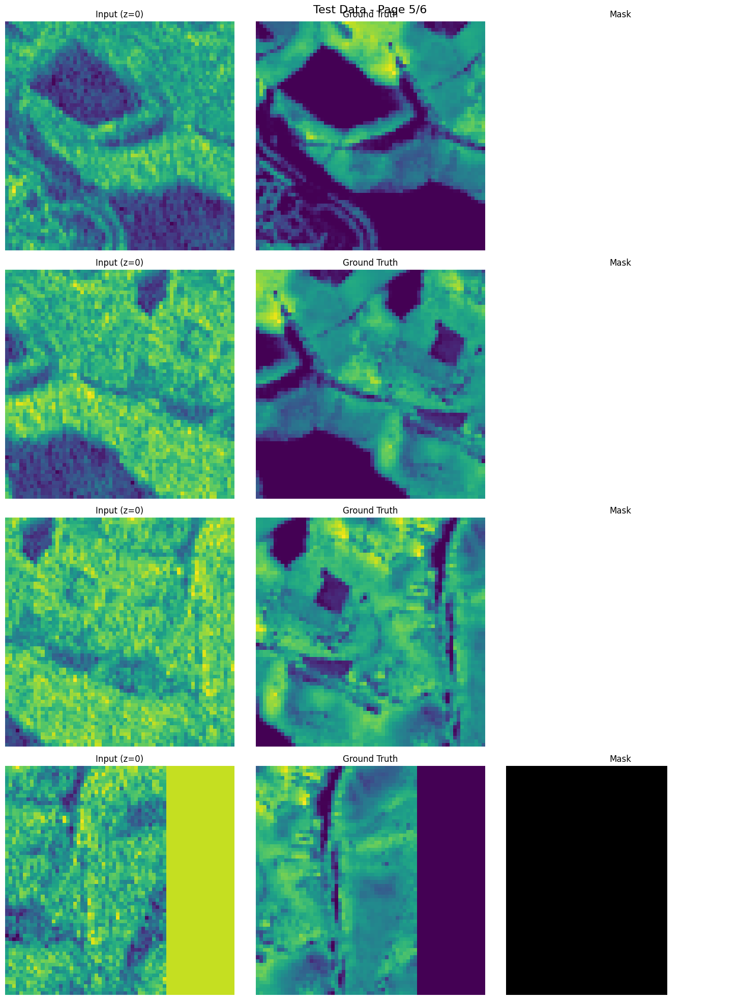

Total samples in Test Data: 24


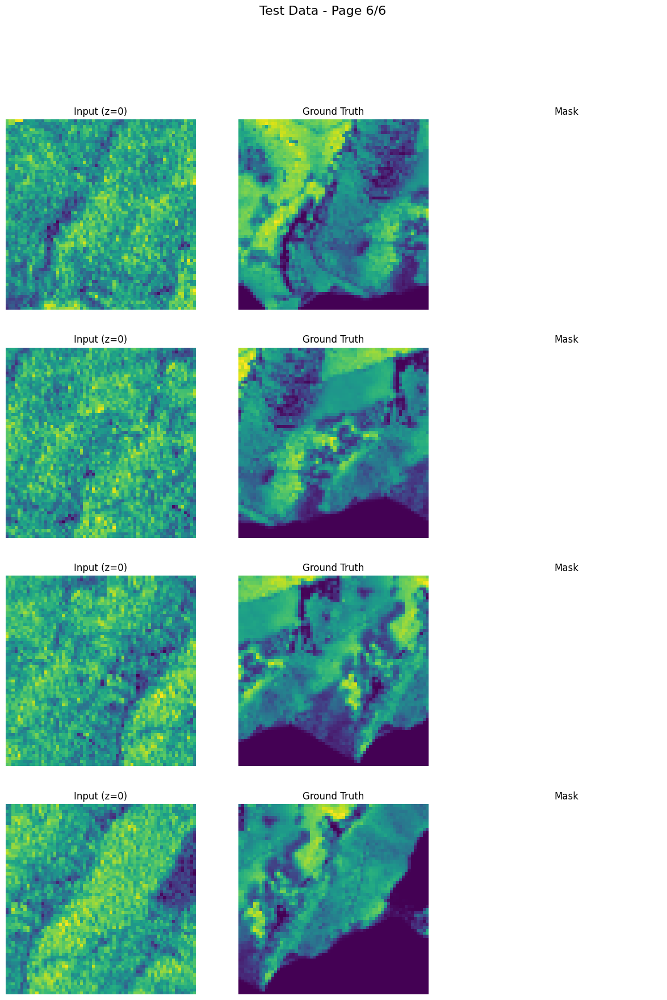

In [12]:
import matplotlib.pyplot as plt
import torch
import math

def visualize_all_samples(loader, dataset_name):
    total_samples = len(loader.dataset)
    samples_per_page = 4
    total_pages = math.ceil(total_samples / samples_per_page)

    sample_index = 0
    for batch_idx, batch in enumerate(loader):
        inputs, targets, masks = batch
        batch_size = inputs.shape[0]

        for i in range(batch_size):
            if sample_index % samples_per_page == 0:
                if sample_index > 0:
                    plt.tight_layout()
                    plt.show()
                fig, axes = plt.subplots(samples_per_page, 3, figsize=(15, 5*samples_per_page))
                page_num = sample_index // samples_per_page + 1
                fig.suptitle(f"{dataset_name} - Page {page_num}/{total_pages}", fontsize=16)

            row = sample_index % samples_per_page

            # Display input (first channel, first depth slice)
            axes[row, 0].imshow(inputs[i, 0, :, :, 0].cpu().numpy())
            axes[row, 0].set_title(f"Input (z=0)")
            axes[row, 0].axis('off')

            # Display ground truth
            axes[row, 1].imshow(targets[i].cpu().numpy())
            axes[row, 1].set_title("Ground Truth")
            axes[row, 1].axis('off')

            # Display mask
            axes[row, 2].imshow(masks[i].cpu().numpy(), cmap='binary')
            axes[row, 2].set_title("Mask")
            axes[row, 2].axis('off')

            sample_index += 1

            if sample_index == total_samples:
                break

        if sample_index == total_samples:
            break

    # Show the last page if it's not full
    if sample_index % samples_per_page != 0:
        plt.tight_layout()
        plt.show()

    print(f"Total samples in {dataset_name}: {sample_index}")

# Visualize all samples from each loader
print("Visualizing Training Data:")
visualize_all_samples(train_loader, "Training Data")

print("\nVisualizing Validation Data:")
visualize_all_samples(val_loader, "Validation Data")

print("\nVisualizing Test Data:")
visualize_all_samples(test_loader, "Test Data")

Dataset Statistics:
{'Quadrant 0': {'total_patches': 40, 'valid_patches': 25, 'invalid_patches': 15, 'invalid_percentage': 37.5}, 'Quadrant 1': {'total_patches': 40, 'valid_patches': 40, 'invalid_patches': 0, 'invalid_percentage': 0.0}, 'Quadrant 2': {'total_patches': 40, 'valid_patches': 27, 'invalid_patches': 13, 'invalid_percentage': 32.5}, 'Quadrant 3': {'total_patches': 40, 'valid_patches': 24, 'invalid_patches': 16, 'invalid_percentage': 40.0}}

Exclusion Statistics:
{'total_patches': 160, 'excluded_patches': 44, 'excluded_due_to_zeros': 38, 'excluded_due_to_nans': 6}
Ground Truth Distribution (Training Set):


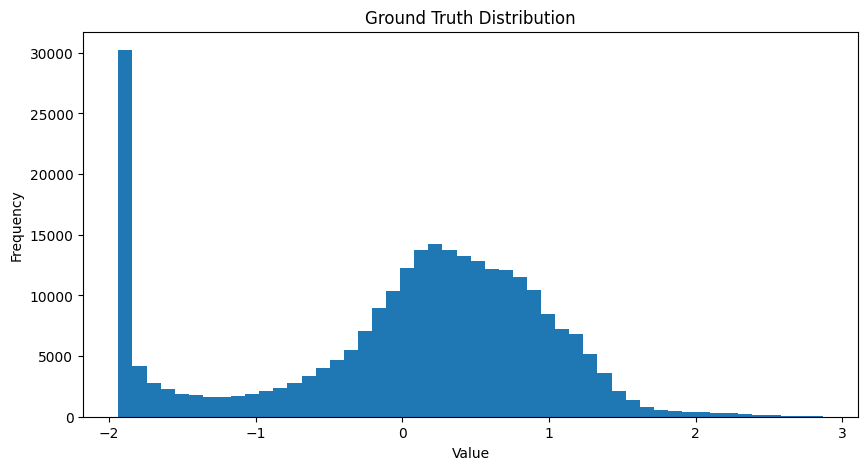

In [13]:





# 8. Dataset statistics
print("Dataset Statistics:")
print(dataset.get_stats())
print("\nExclusion Statistics:")
print(dataset.get_exclusion_stats())

# 9. Check ground truth distribution
def plot_gt_distribution(loader):
    all_gt = []
    for batch in loader:
        all_gt.append(batch[1])
    all_gt = torch.cat(all_gt, dim=0)
    
    plt.figure(figsize=(10, 5))
    plt.hist(all_gt.numpy().flatten(), bins=50)
    plt.title("Ground Truth Distribution")
    plt.xlabel("Value")
    plt.ylabel("Frequency")
    plt.show()

print("Ground Truth Distribution (Training Set):")
plot_gt_distribution(train_loader)

In [14]:
# batching is working and so is padding and mask :) 

In [15]:
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
import os
import math
import numpy as np

def plot_all_dataloader_samples(dataloader, output_dir='train_samples_plots'):
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    total_samples = len(dataloader)
    samples_with_false = 0
    samples_per_figure = 20
    figures_count = math.ceil(total_samples / samples_per_figure)

    dataloader_iter = iter(dataloader)

    for figure_index in range(figures_count):
        fig, axes = plt.subplots(samples_per_figure, 3, figsize=(15, 5*samples_per_figure))
        
        for i in range(samples_per_figure):
            sample_index = figure_index * samples_per_figure + i
            if sample_index >= total_samples:
                break

            try:
                intensity, ground_truth, mask = next(dataloader_iter)
            except StopIteration:
                break
            
            # Get the first item in the batch
            intensity = intensity[0]
            ground_truth = ground_truth[0]
            mask = mask[0]
            
            # Plot intensity (use the middle slice of the 3D volume)
            middle_slice = intensity.shape[2] // 2
            axes[i, 0].imshow(intensity[0, :, :, middle_slice].cpu().numpy(), cmap='gray')
            axes[i, 0].set_title(f'Intensity (Sample {sample_index+1}, Slice {middle_slice})')
            axes[i, 0].axis('off')
            
            # Plot ground truth
            axes[i, 1].imshow(ground_truth.cpu().numpy(), cmap='viridis')
            axes[i, 1].set_title(f'Ground Truth (Sample {sample_index+1})')
            axes[i, 1].axis('off')
            
            # Plot mask
            axes[i, 2].imshow(mask.cpu().numpy(), cmap='binary')
            axes[i, 2].set_title(f'Mask (Sample {sample_index+1})')
            axes[i, 2].axis('off')
            
            # Check for False values in mask
            if not torch.all(mask):
                samples_with_false += 1
                print(f"Sample {sample_index+1} has False values in mask")

            # Print mask statistics
            true_count = mask.sum().item()
            total_count = mask.numel()
            print(f"Sample {sample_index+1} - True values in mask: {true_count}/{total_count} ({true_count/total_count*100:.2f}%)")

        # Remove empty subplots if any
        for j in range(i+1, samples_per_figure):
            for k in range(3):
                fig.delaxes(axes[j, k])

        plt.tight_layout()
        plt.savefig(os.path.join(output_dir, f'samples_{figure_index+1}.png'), dpi=300, bbox_inches='tight')
        plt.close(fig)

    print(f"\nTotal samples checked: {total_samples}")
    print(f"Samples with False values in mask: {samples_with_false}")
    print(f"Percentage of samples with False values: {samples_with_false/total_samples*100:.2f}%")

# Assuming you have your dataset and dataloader set up
dataset.set_mode('train')
train_loader = DataLoader(dataset, batch_size=1, shuffle=False)  # Set shuffle to False to maintain order

# Plot all samples and check masks
plot_all_dataloader_samples(train_loader)

Sample 1 - True values in mask: 4096/4096 (100.00%)
Sample 2 has False values in mask
Sample 2 - True values in mask: 2816/4096 (68.75%)
Sample 3 - True values in mask: 4096/4096 (100.00%)
Sample 4 - True values in mask: 4096/4096 (100.00%)
Sample 5 - True values in mask: 4096/4096 (100.00%)
Sample 6 - True values in mask: 4096/4096 (100.00%)
Sample 7 - True values in mask: 4096/4096 (100.00%)
Sample 8 - True values in mask: 4096/4096 (100.00%)
Sample 9 has False values in mask
Sample 9 - True values in mask: 2816/4096 (68.75%)
Sample 10 - True values in mask: 4096/4096 (100.00%)
Sample 11 - True values in mask: 4096/4096 (100.00%)
Sample 12 - True values in mask: 4096/4096 (100.00%)
Sample 13 - True values in mask: 4096/4096 (100.00%)
Sample 14 - True values in mask: 4096/4096 (100.00%)
Sample 15 has False values in mask
Sample 15 - True values in mask: 2816/4096 (68.75%)
Sample 16 - True values in mask: 4096/4096 (100.00%)
Sample 17 - True values in mask: 4096/4096 (100.00%)
Sample 1

Sample 41 - True values in mask: 4096/4096 (100.00%)
Sample 42 - True values in mask: 4096/4096 (100.00%)
Sample 43 - True values in mask: 4096/4096 (100.00%)
Sample 44 - True values in mask: 4096/4096 (100.00%)
Sample 45 has False values in mask
Sample 45 - True values in mask: 2880/4096 (70.31%)
Sample 46 - True values in mask: 4096/4096 (100.00%)
Sample 47 - True values in mask: 4096/4096 (100.00%)
Sample 48 - True values in mask: 4096/4096 (100.00%)
Sample 49 - True values in mask: 4096/4096 (100.00%)
Sample 50 - True values in mask: 4096/4096 (100.00%)
Sample 51 - True values in mask: 4096/4096 (100.00%)
Sample 52 - True values in mask: 4096/4096 (100.00%)
Sample 53 - True values in mask: 4096/4096 (100.00%)
Sample 54 - True values in mask: 4096/4096 (100.00%)
Sample 55 has False values in mask
Sample 55 - True values in mask: 2880/4096 (70.31%)
Sample 56 - True values in mask: 4096/4096 (100.00%)
Sample 57 - True values in mask: 4096/4096 (100.00%)
Sample 58 - True values in mask

In [16]:
len(train_loader)

65

3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


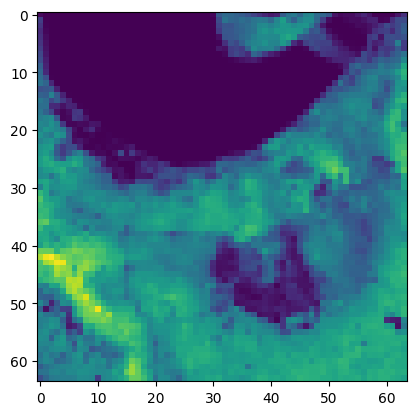

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


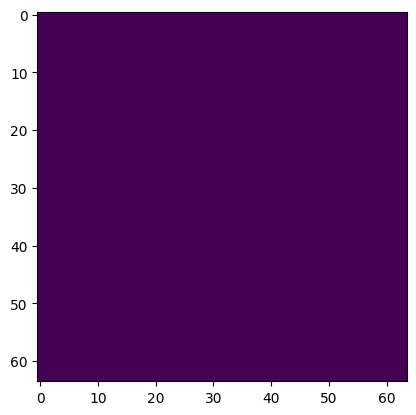

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


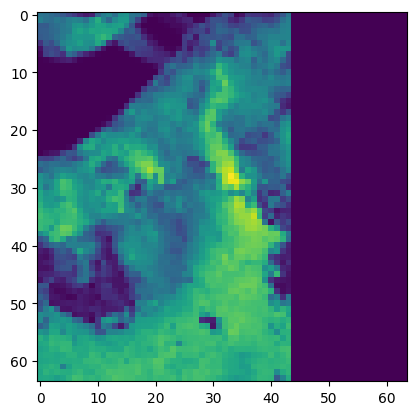

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


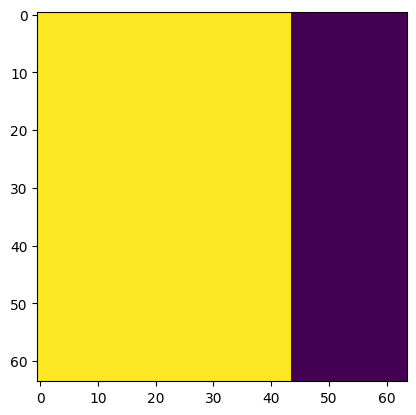

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


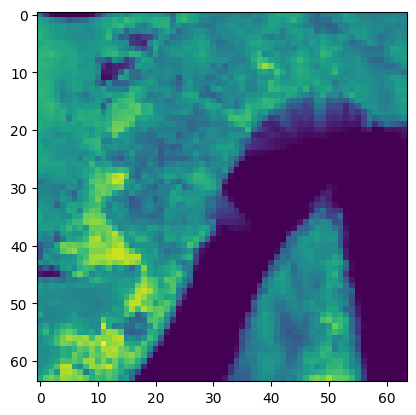

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


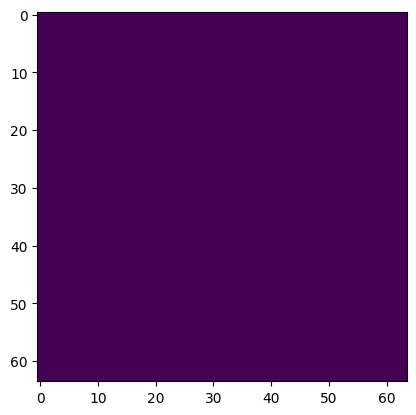

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


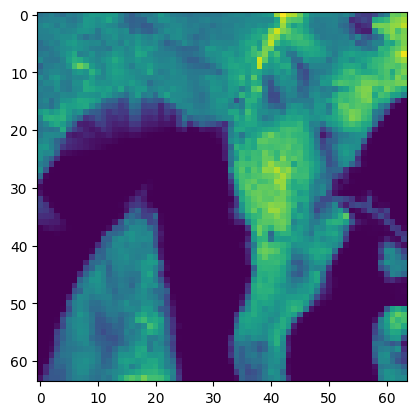

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


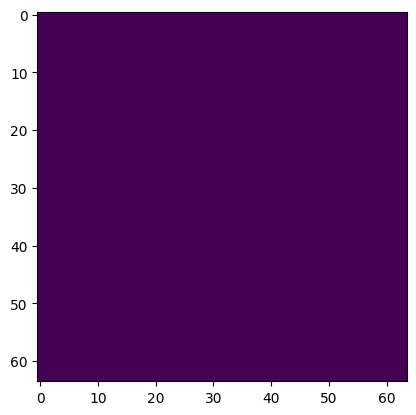

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


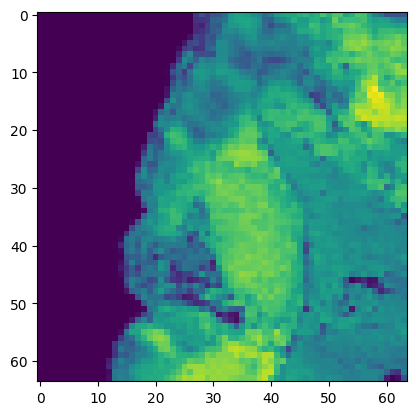

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


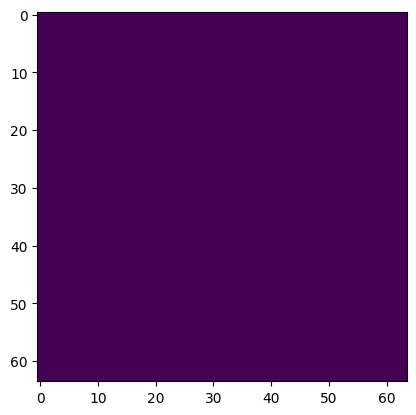

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


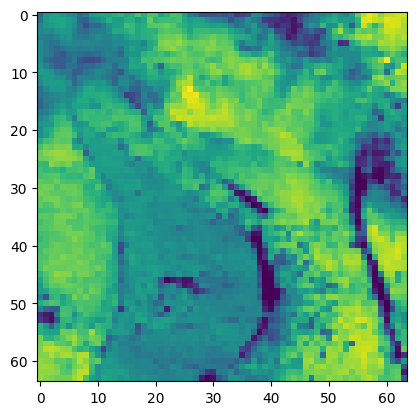

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


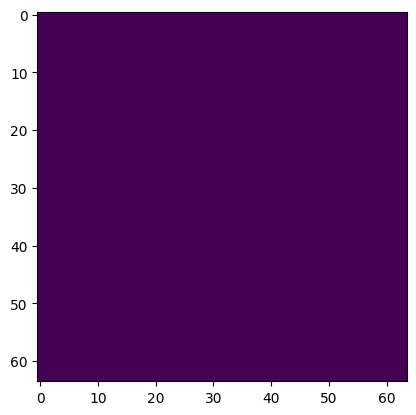

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


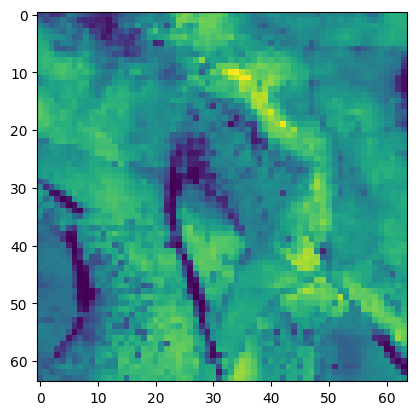

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


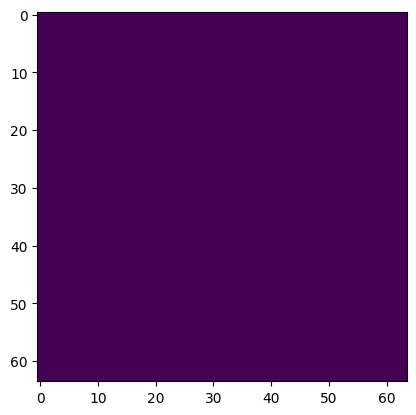

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


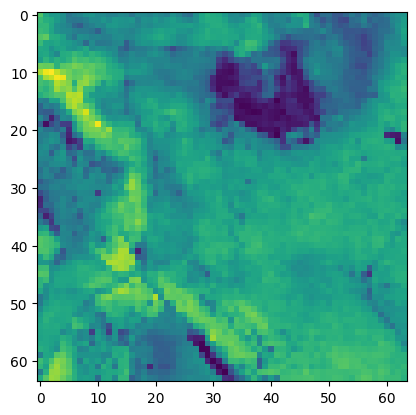

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


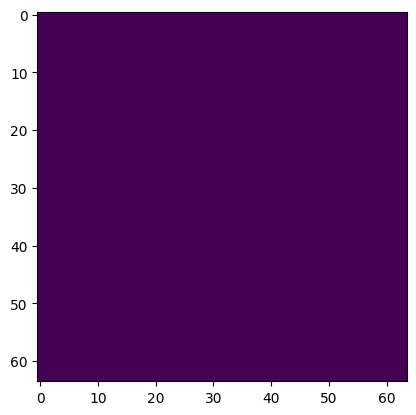

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


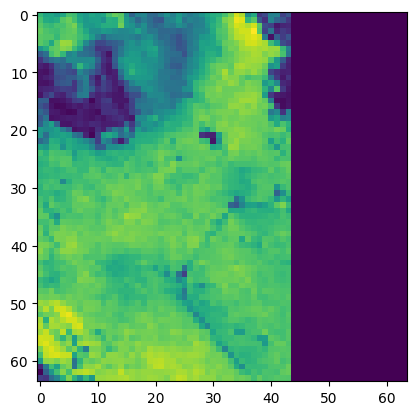

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


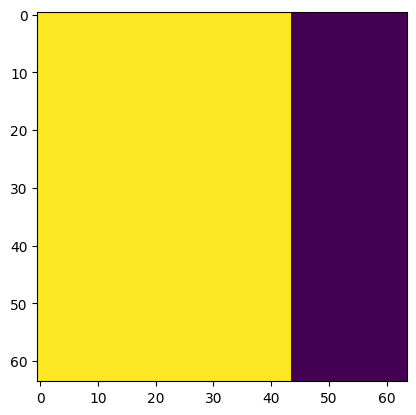

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


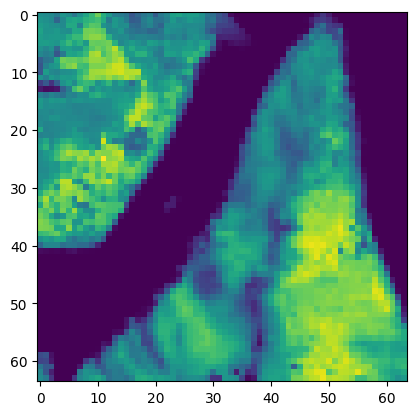

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


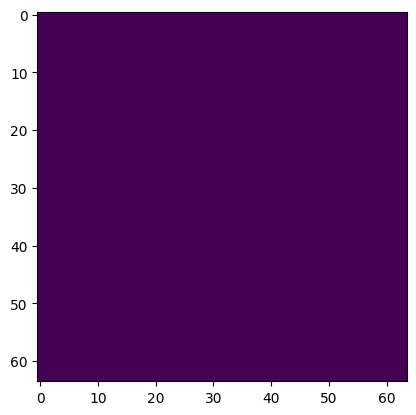

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


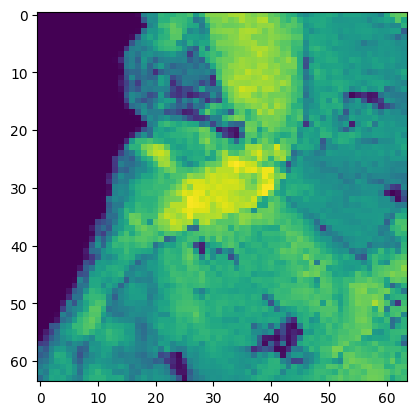

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


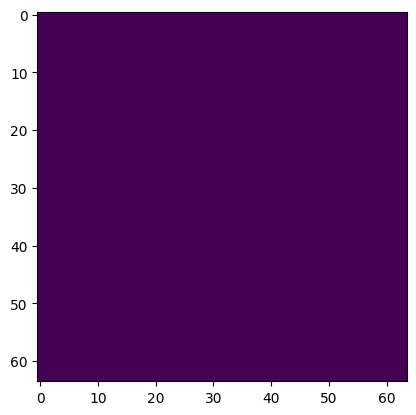

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


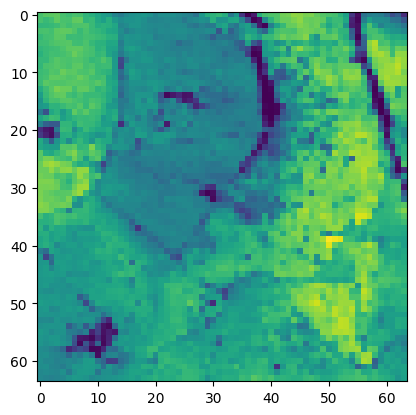

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


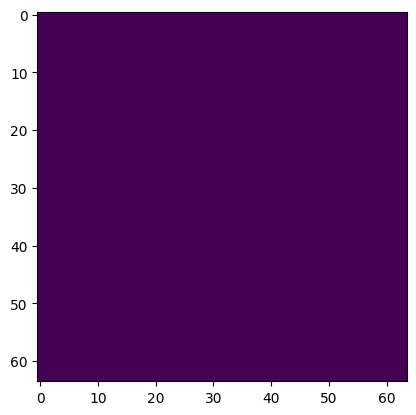

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


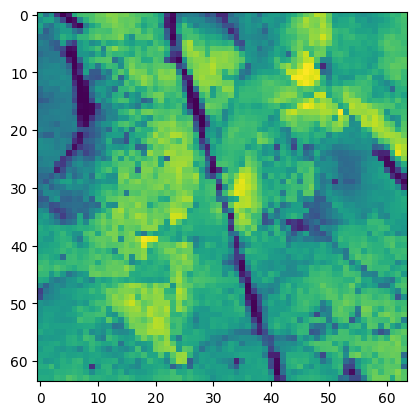

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


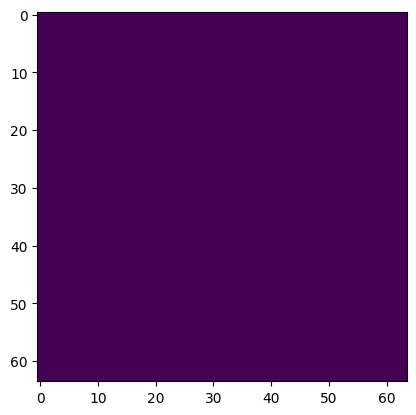

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


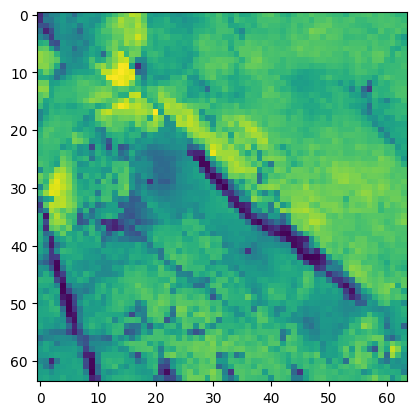

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


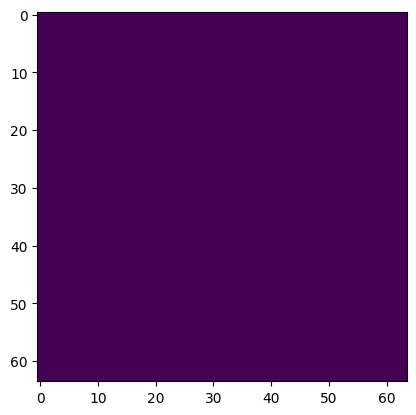

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


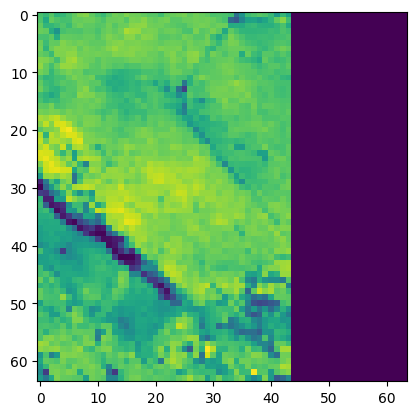

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


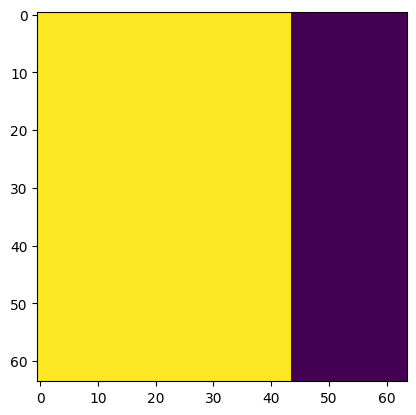

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


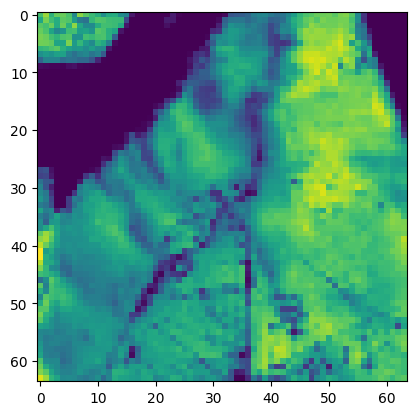

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


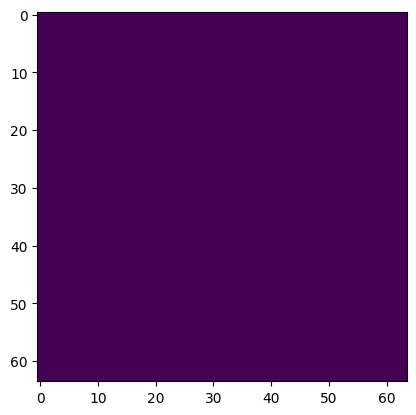

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


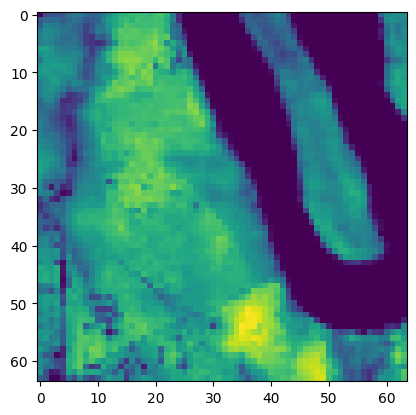

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


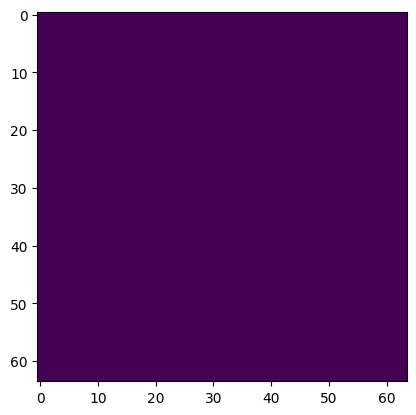

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


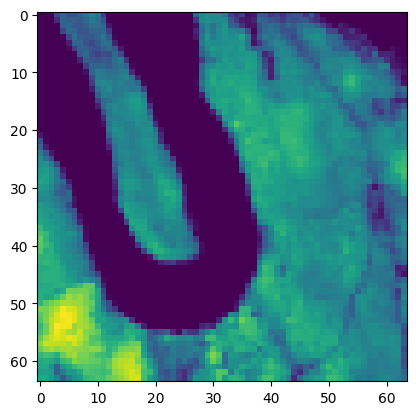

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


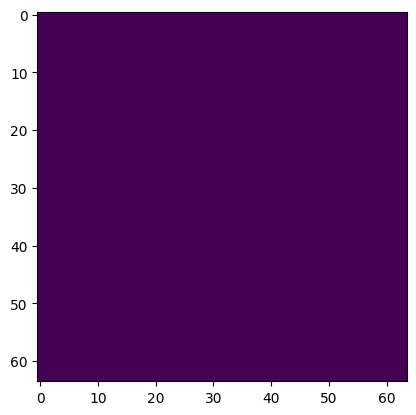

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


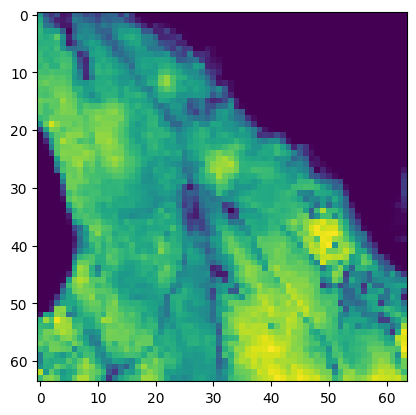

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


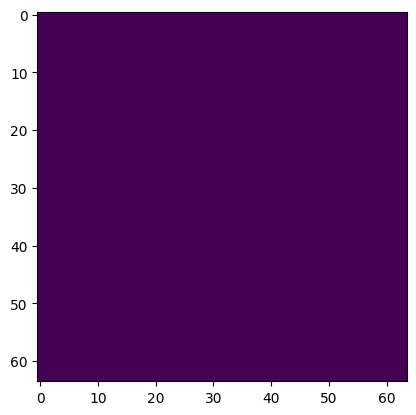

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


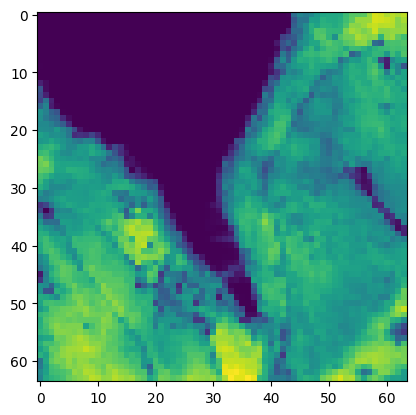

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


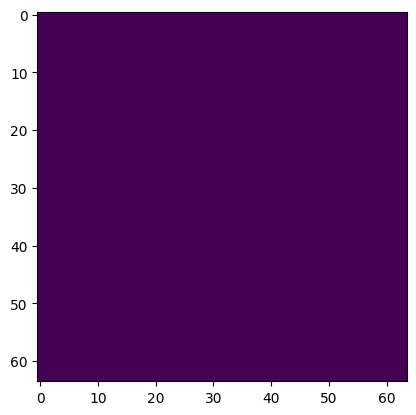

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


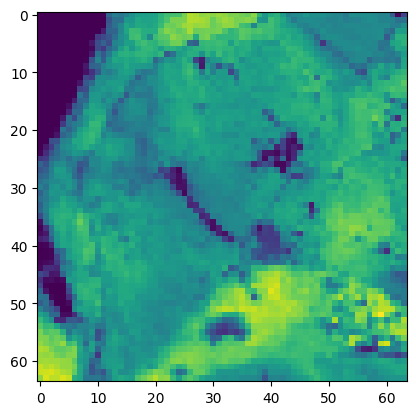

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


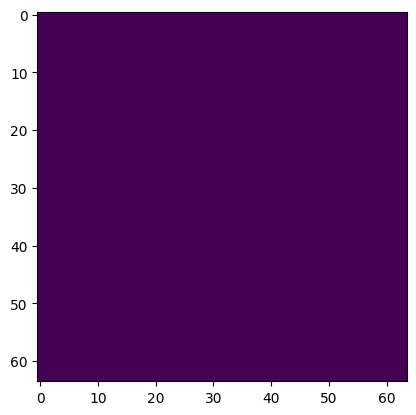

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


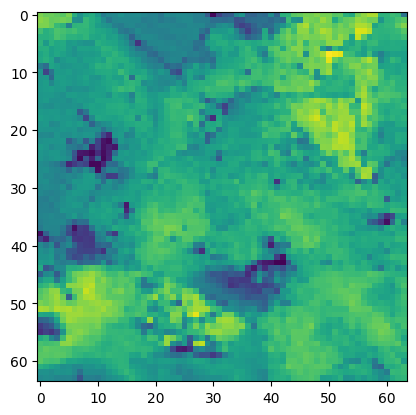

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


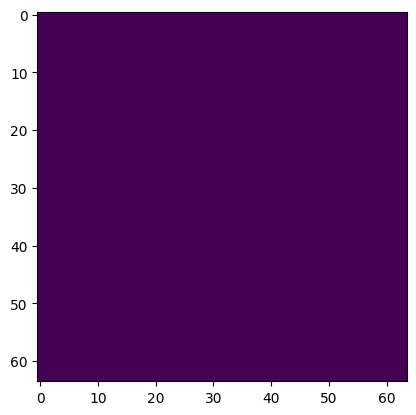

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


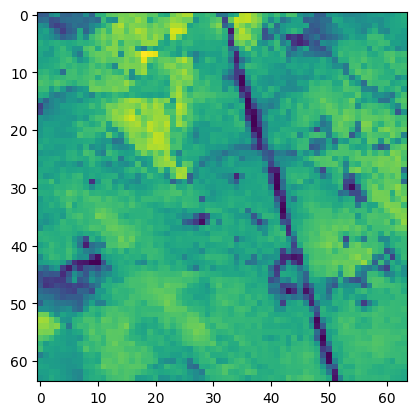

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


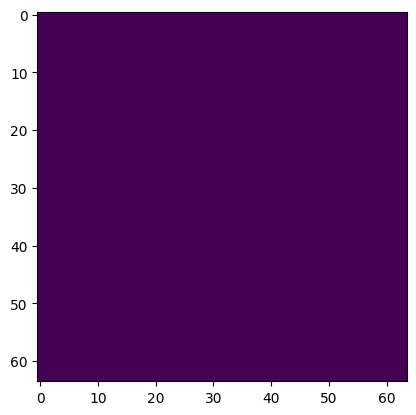

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


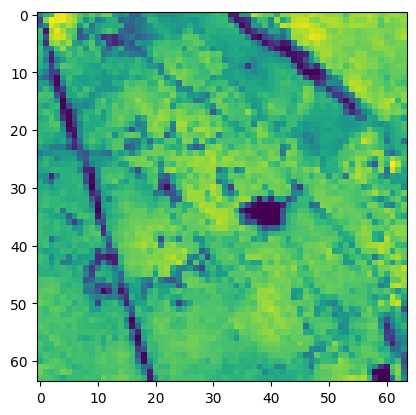

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


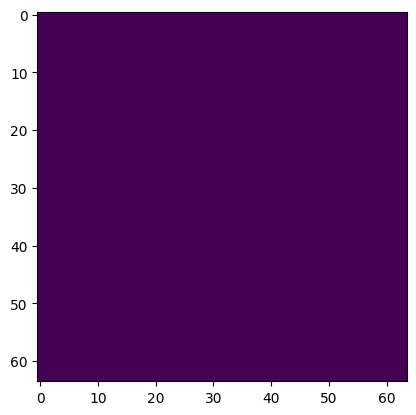

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


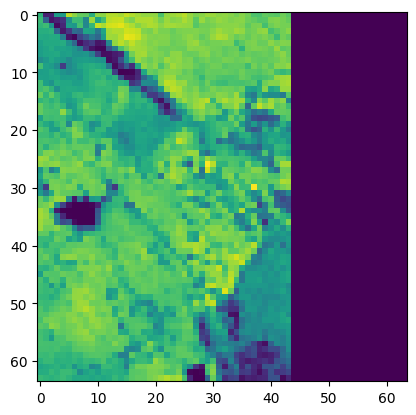

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


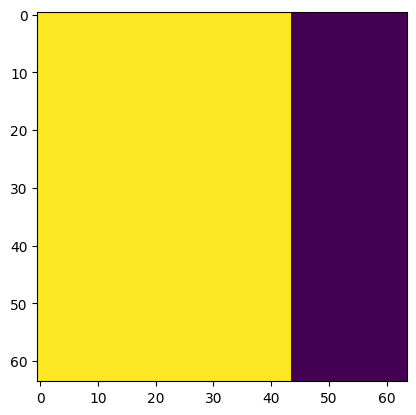

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


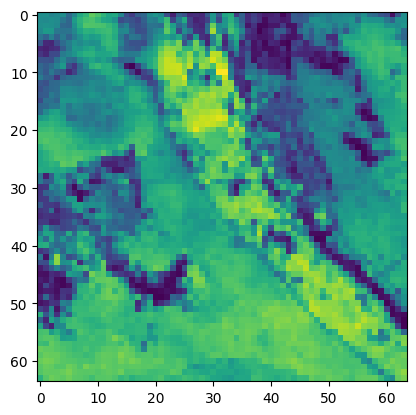

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


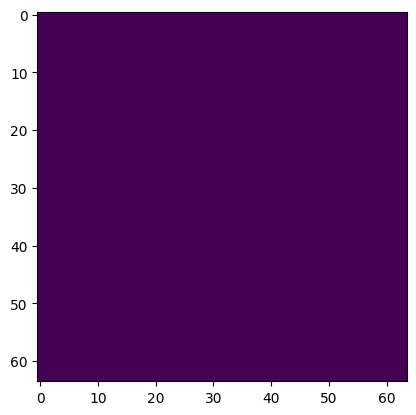

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


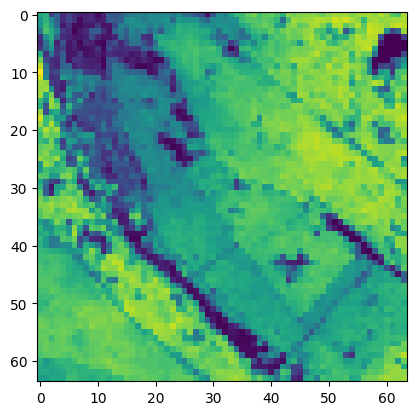

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


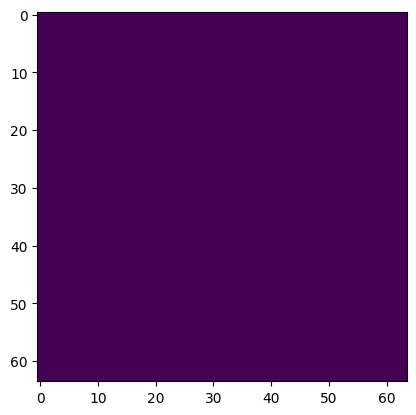

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


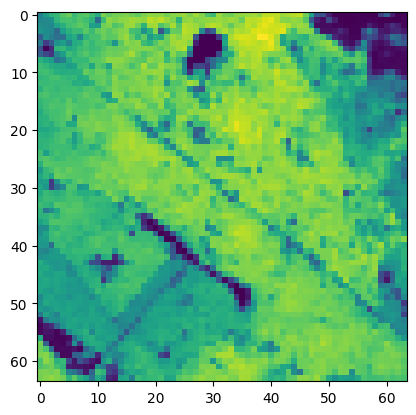

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


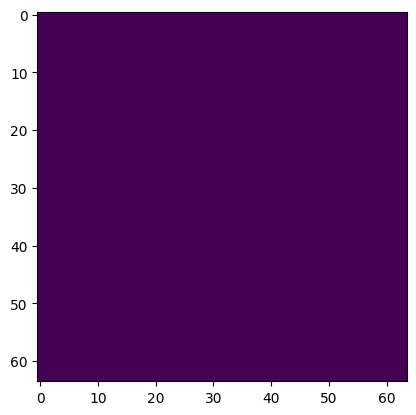

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


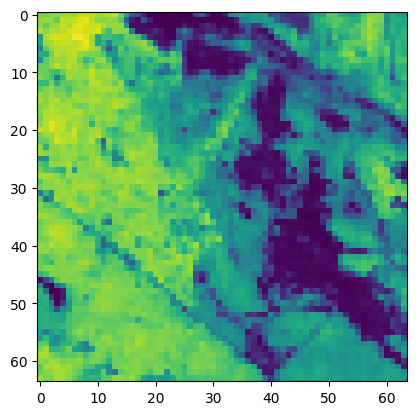

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


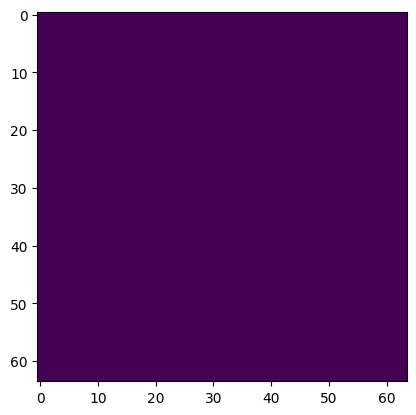

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


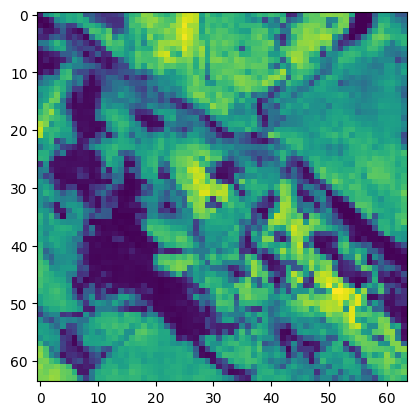

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


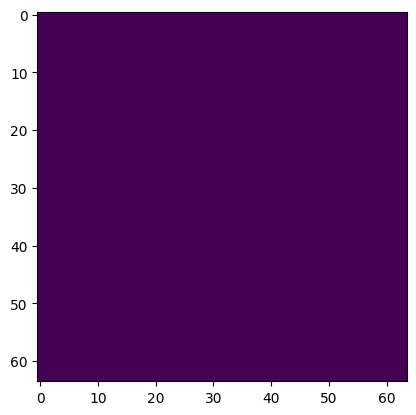

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


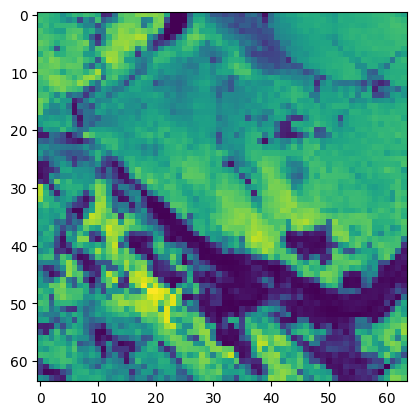

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


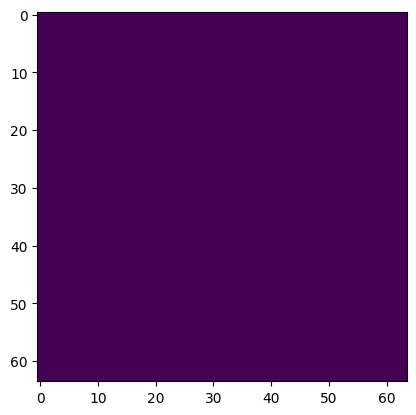

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


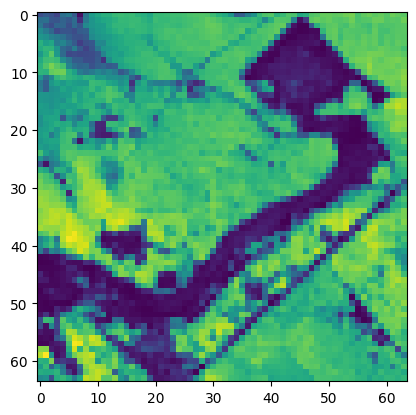

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


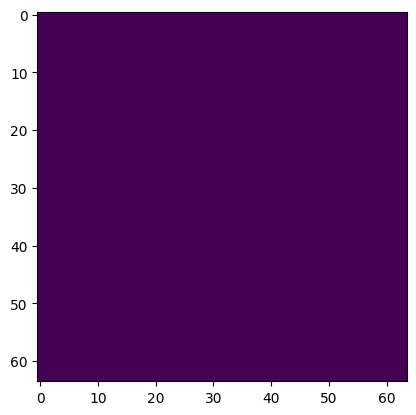

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


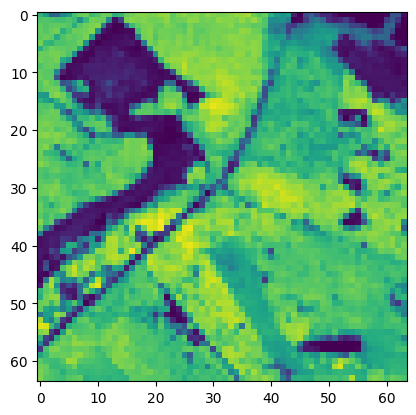

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


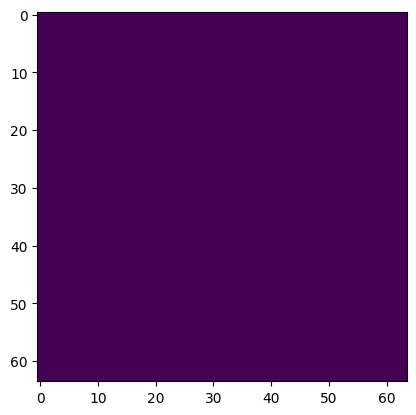

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


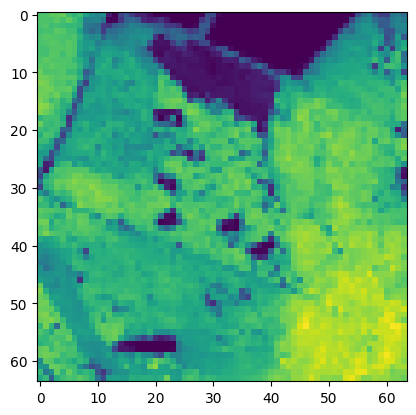

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


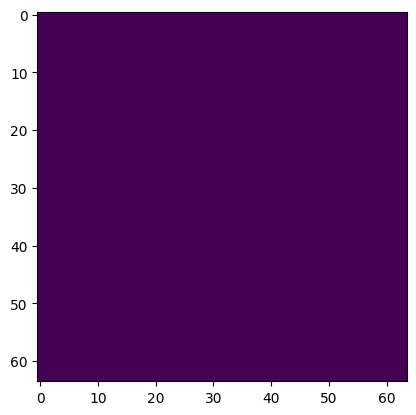

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


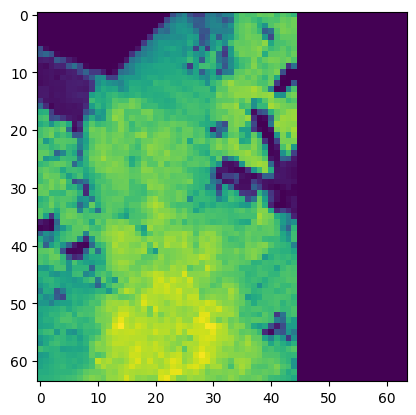

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


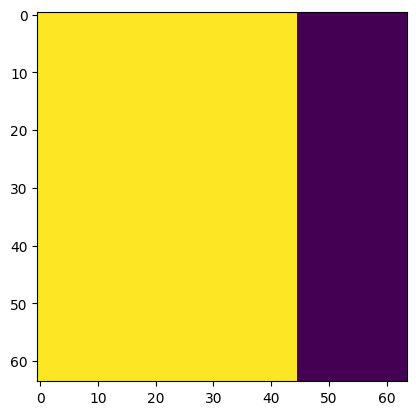

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


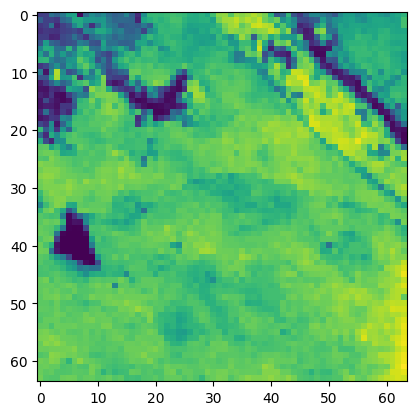

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


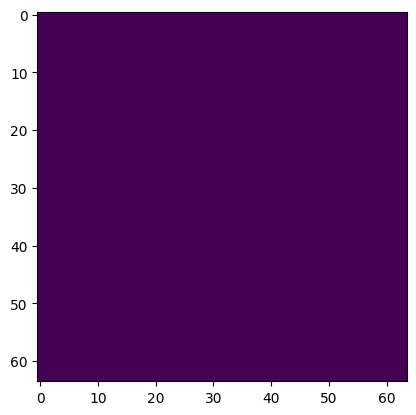

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


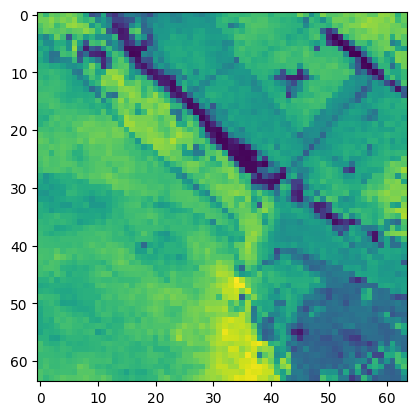

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


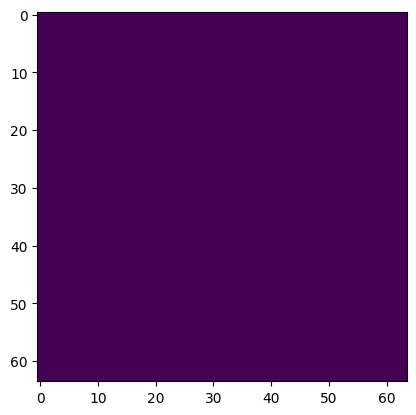

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


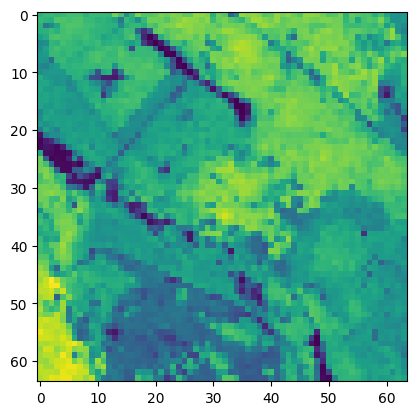

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


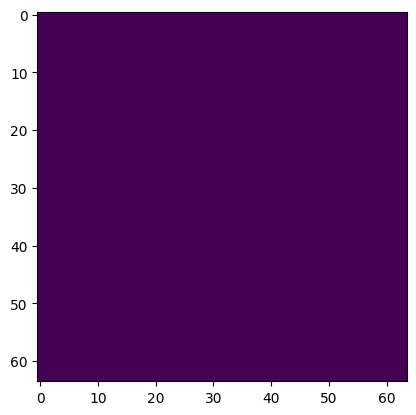

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


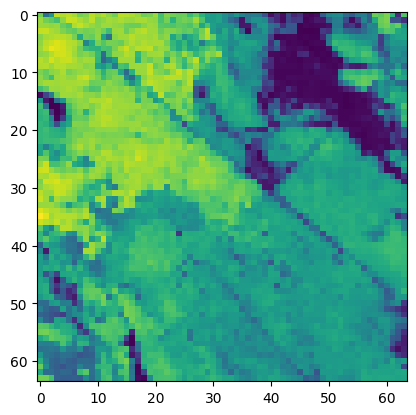

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


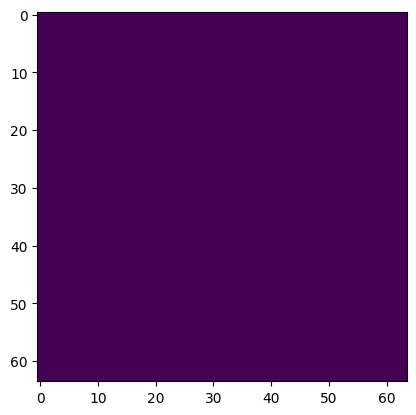

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


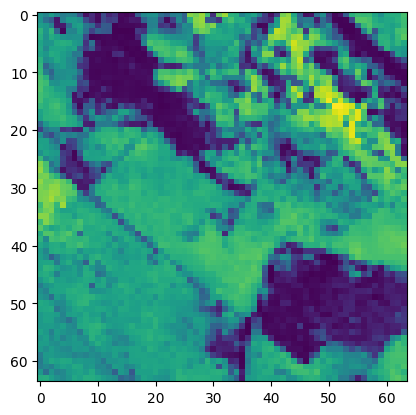

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


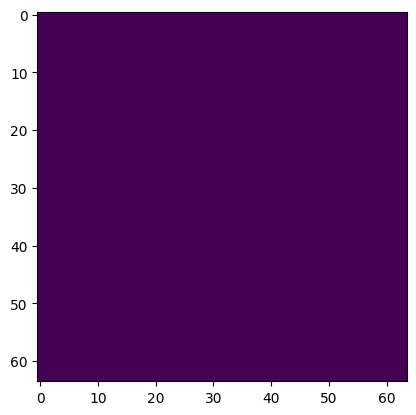

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


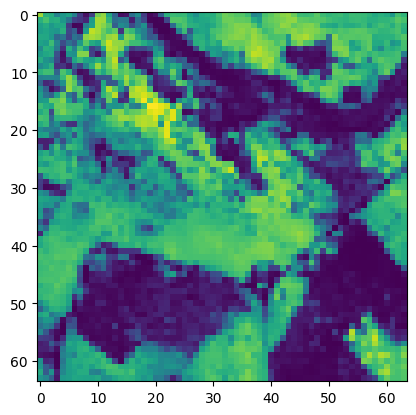

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


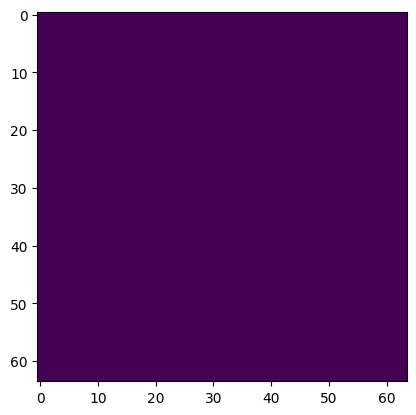

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


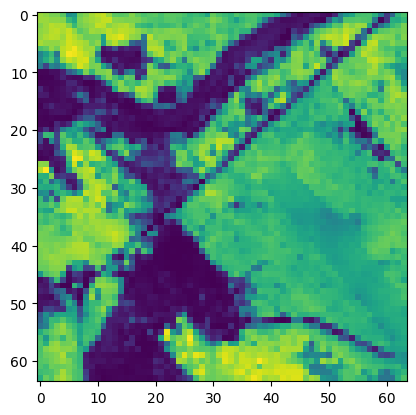

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


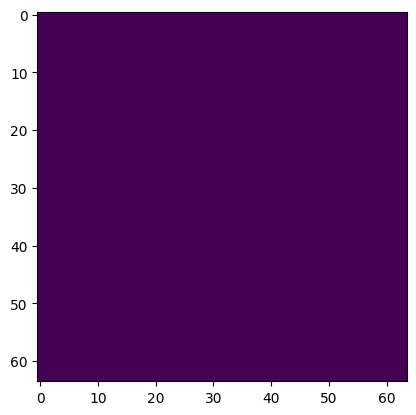

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


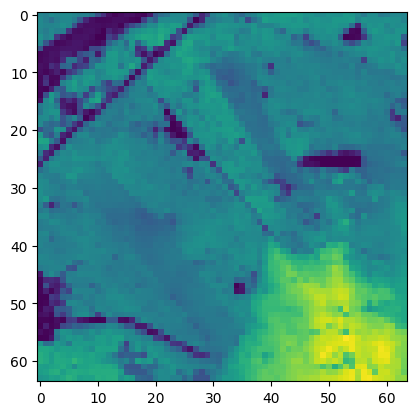

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


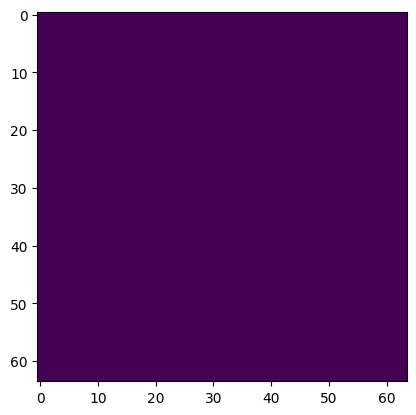

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


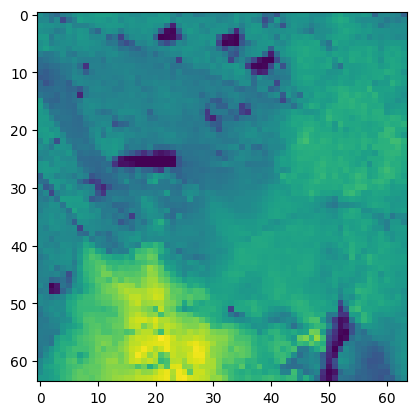

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


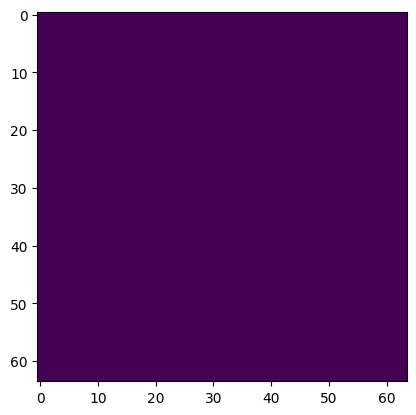

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


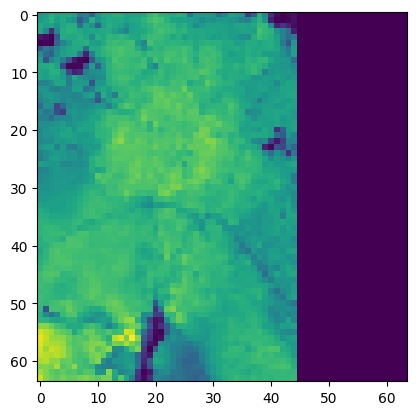

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


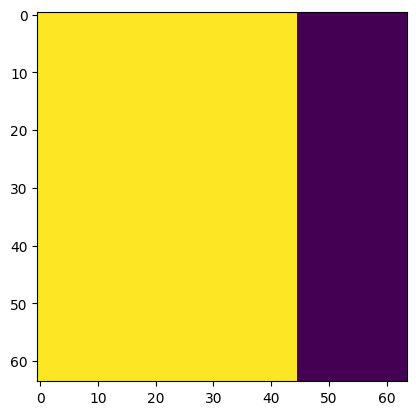

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


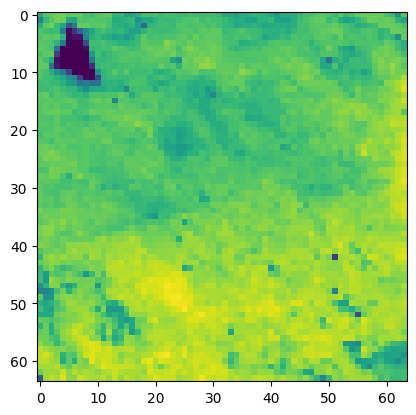

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


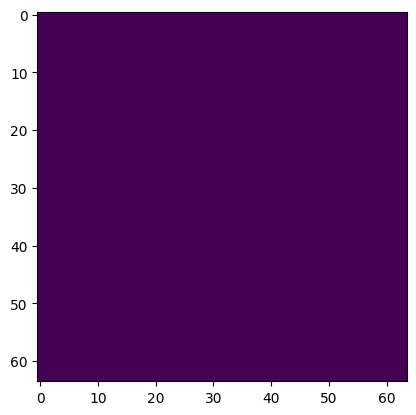

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


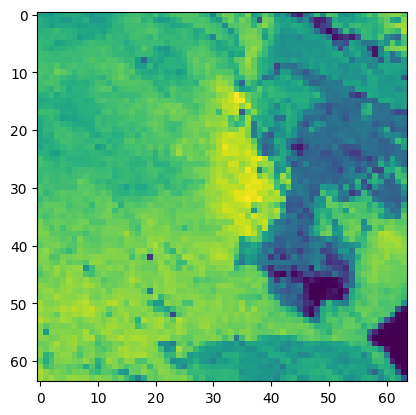

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


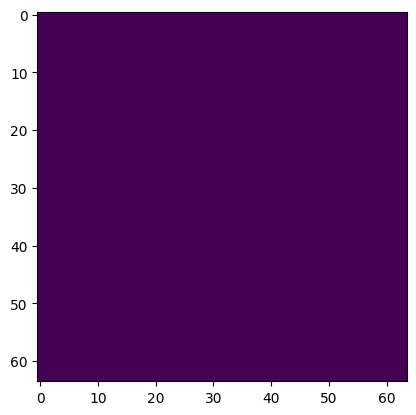

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


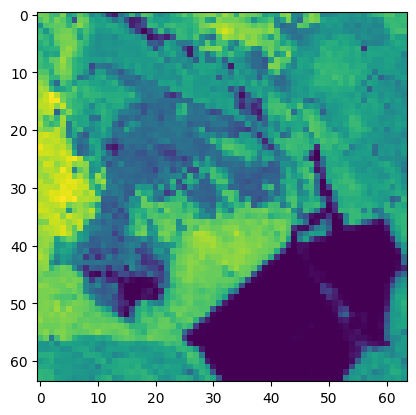

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


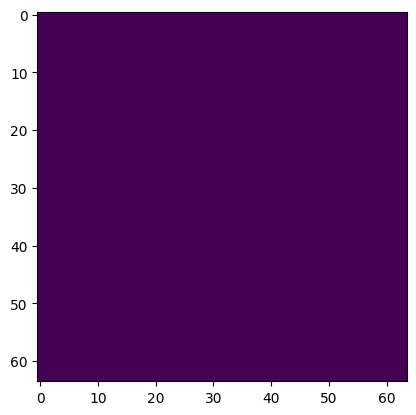

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


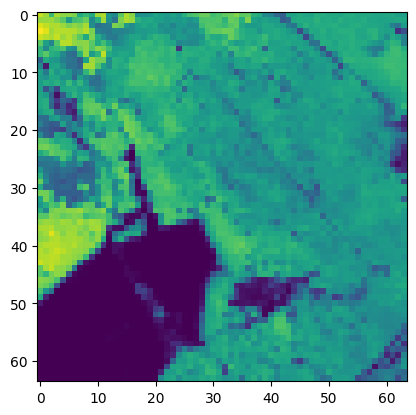

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


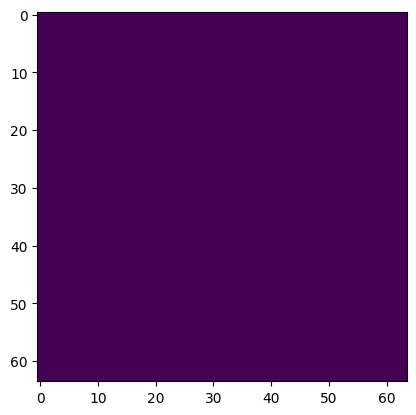

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


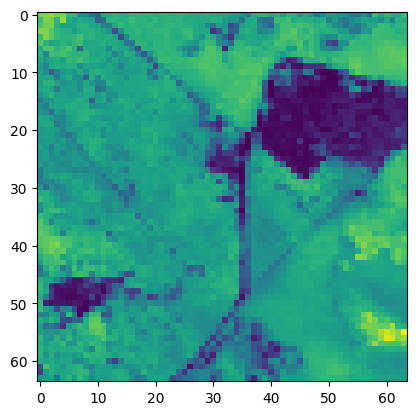

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


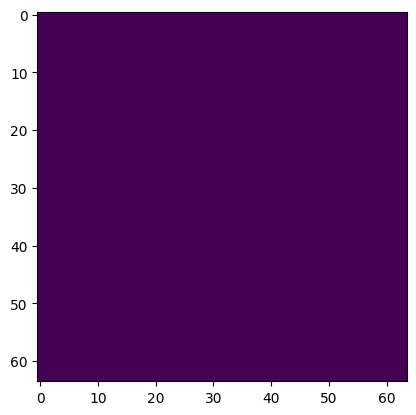

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


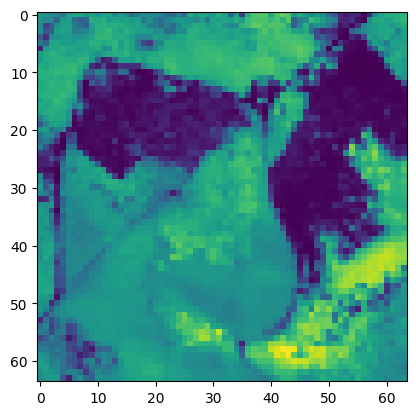

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


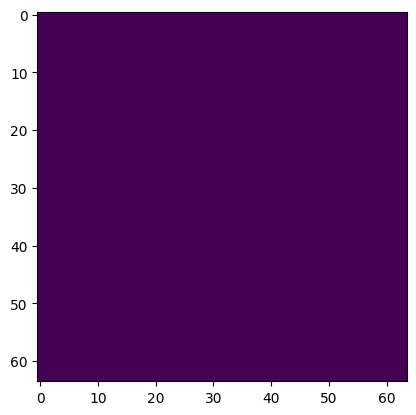

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


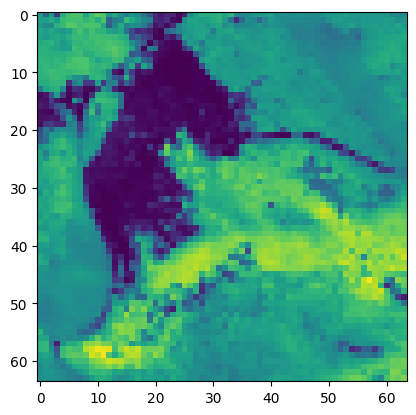

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


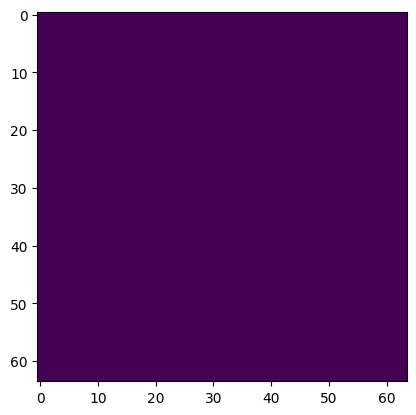

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


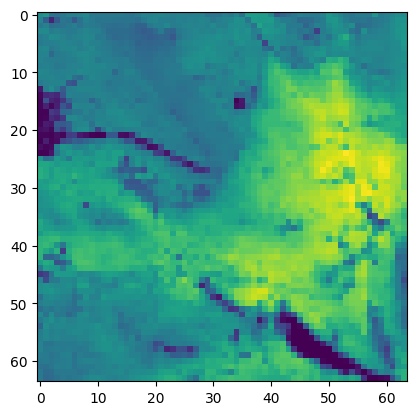

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


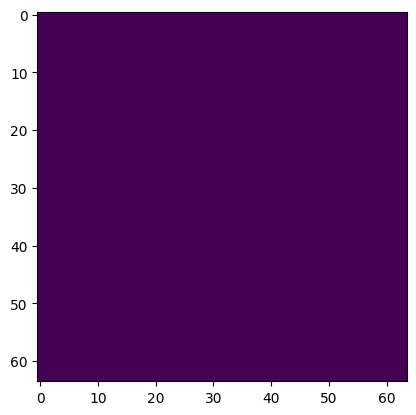

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


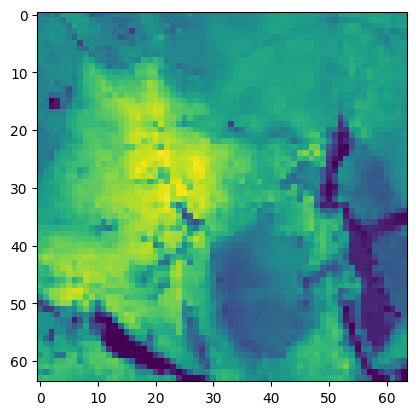

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


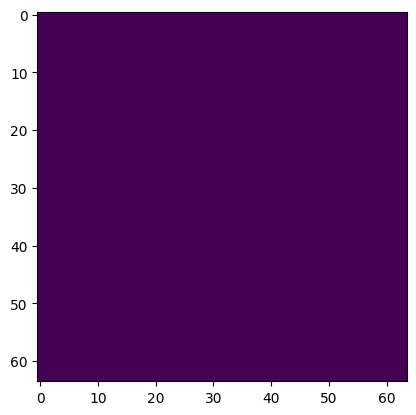

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


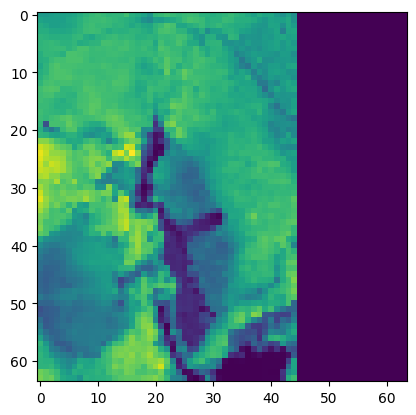

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


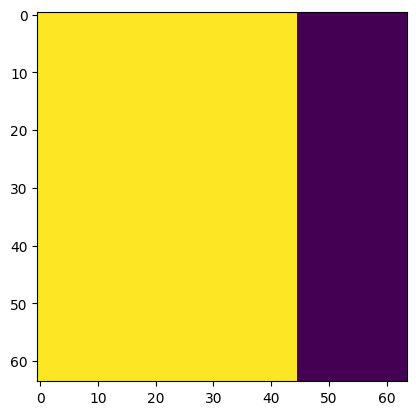

tensor(False)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


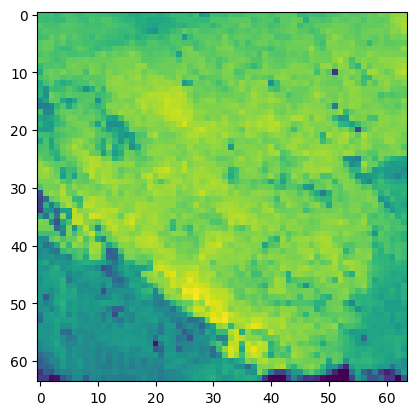

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


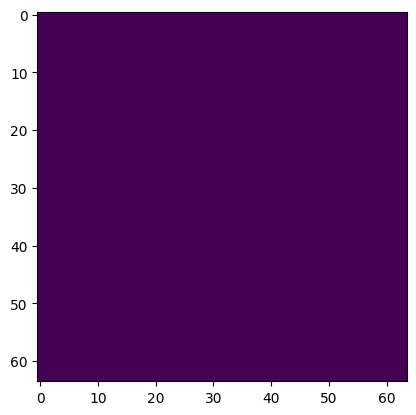

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


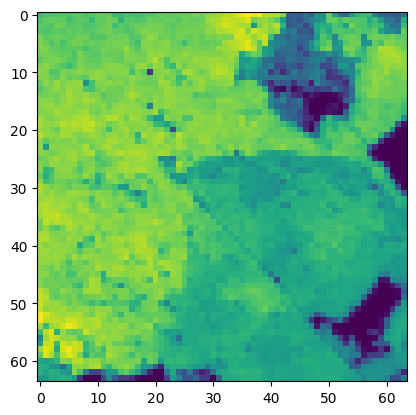

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


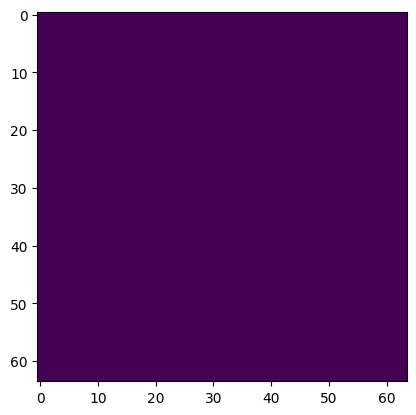

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


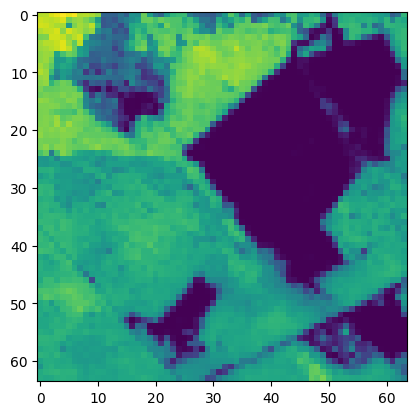

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


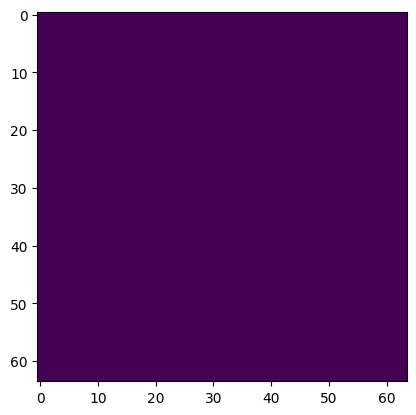

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


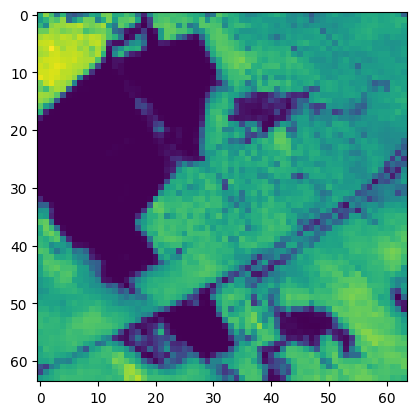

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


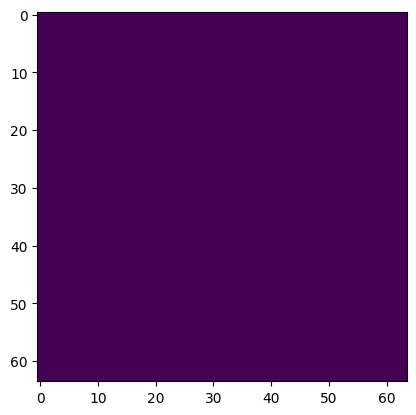

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


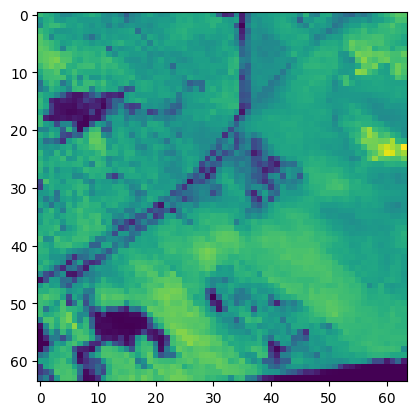

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


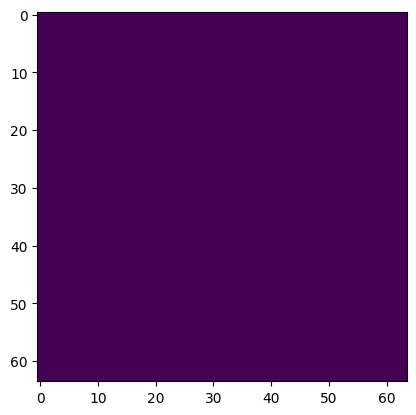

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


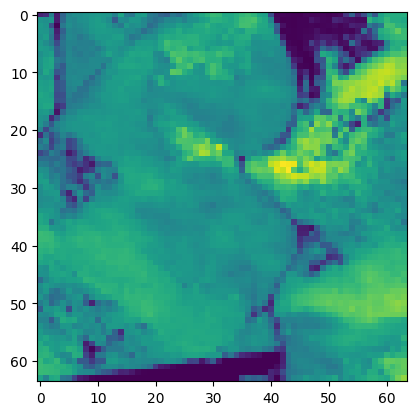

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


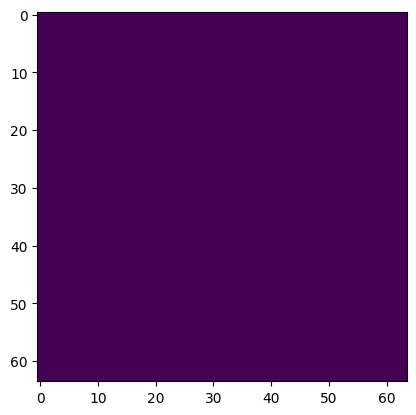

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


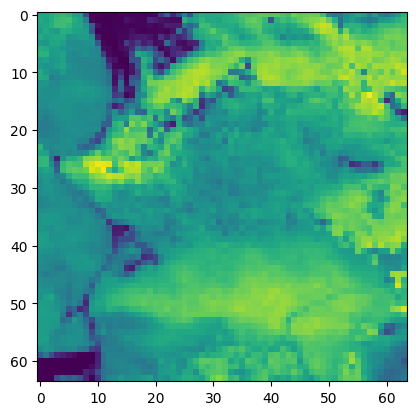

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


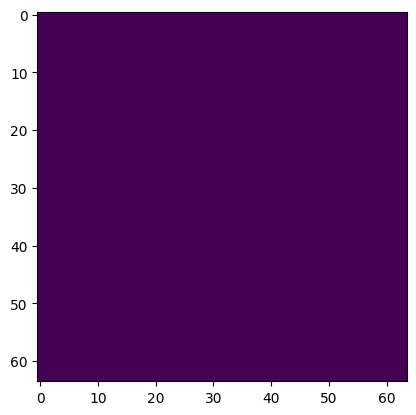

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


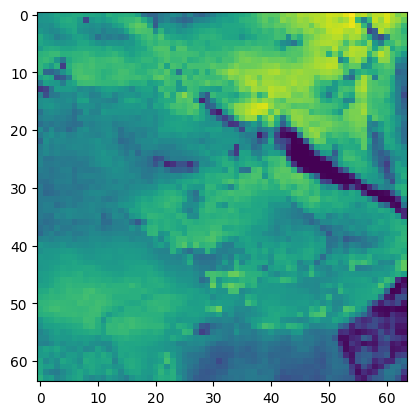

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


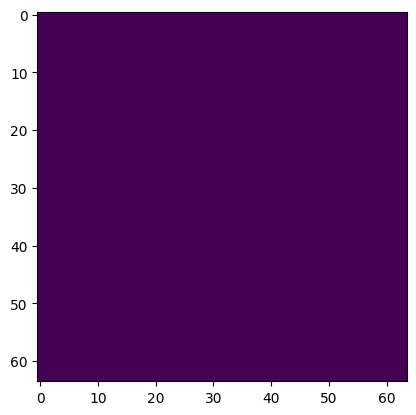

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


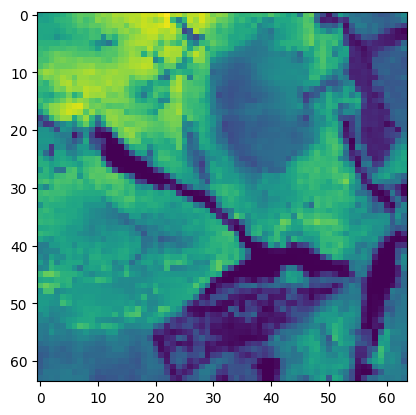

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


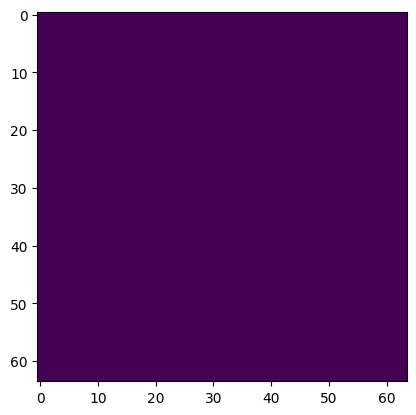

tensor(True)
3
torch.Size([1, 3, 64, 64, 36])
torch.Size([1, 64, 64])
torch.Size([1, 64, 64])


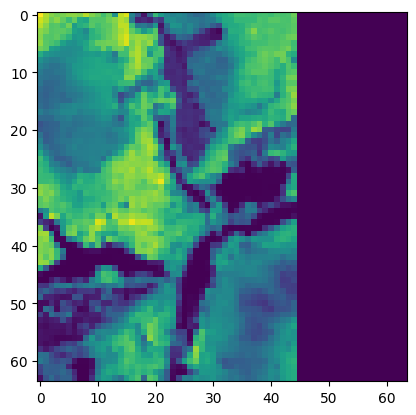

tensor([[ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        ...,
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False],
        [ True,  True,  True,  ..., False, False, False]])


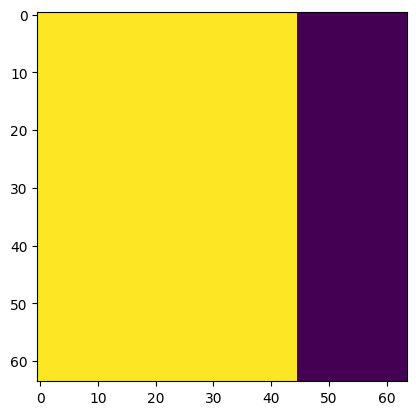

tensor(False)


In [17]:
for batch in train_loader:
    print(len(batch))
    print(batch[0].shape)
    print(batch[1].shape)
    print(batch[2].shape)
    plt.imshow(batch[1][0,:,:])
    plt.show()
    plt.imshow(batch[2][0,:,:])
    print(batch[2][0, :,:])
    plt.show() 
    print(batch[2][0, :, :].min())

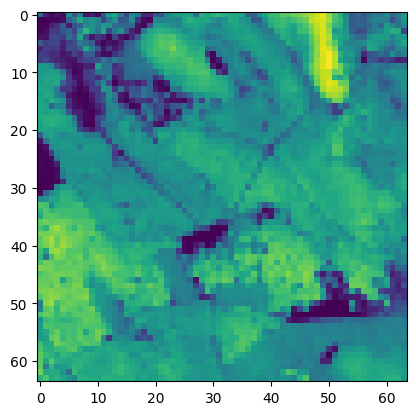

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


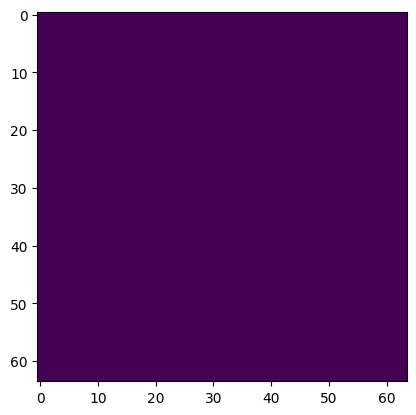

tensor(True)


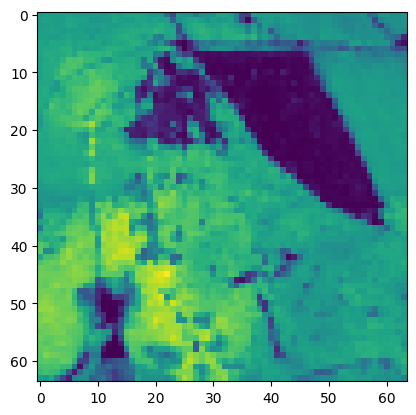

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])


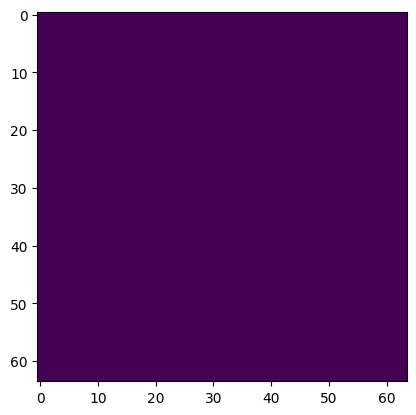

tensor(True)


In [18]:
for batch in val_loader:
    # print(len(batch))
    # print(batch[0].shape)
    # print(batch[1].shape)
    # print(batch[2].shape)
    plt.imshow(batch[1][0,:,:])
    plt.show()
    plt.imshow(batch[2][0,:,:])
    print(batch[2][0, :,:])
    plt.show() 
    print(batch[2][0, :, :].min())

In [19]:
for batch in val_loader:
    print(len(batch))
    print(batch[0].shape)
    print(batch[1].shape)
    print(batch[2].shape)


3
torch.Size([20, 3, 64, 64, 36])
torch.Size([20, 64, 64])
torch.Size([20, 64, 64])
3
torch.Size([7, 3, 64, 64, 36])
torch.Size([7, 64, 64])
torch.Size([7, 64, 64])
